# Projet Data Mining - Analyse des données publiques

## 1. Introduction

Notre objectif est d'explorer ces données pour identifier des relations, des comportements récurrents et d'éventuelles anomalies.

L'analyse porte sur les neuf fichiers CSV du dossier `public_records`.

Nous allons commencer par explorer et nettoyer les données, puis utiliser différentes méthodes de Data Mining pour rechercher des liens entre les personnes, les organisations et les événements.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
dossier = Path("data/public_records")

fichiers = [
    "institutional_memos",
    "licensed_facilities",
    "licensed_professionals",
    "officer_filings",
    "public_and_investigative_documents",
    "public_appointments",
    "registered_entities",
    "regulatory_case_events",
    "site_access_case_events"
]

donnees = {}

for fichier in fichiers:
    donnees[fichier] = pd.read_csv(dossier / f"{fichier}.csv")

print("Nombre de fichiers chargés :", len(donnees))

Nombre de fichiers chargés : 9


## 2. Exploration générale des données

Nous commençons par examiner la structure des neuf fichiers.

Cette première exploration permet de connaître le nombre de lignes et de colonnes de chaque fichier, afin de mieux comprendre les données disponibles avant de commencer leur nettoyage.

In [3]:
resume = []

for nom, df in donnees.items():
    resume.append({
        "Fichier": nom,
        "Nombre de lignes": df.shape[0],
        "Nombre de colonnes": df.shape[1]
    })

resume_df = pd.DataFrame(resume)

display(resume_df)

,Fichier,Nombre de lignes,Nombre de colonnes
0,institutional_memos,30,12
1,licensed_facilities,3,12
2,licensed_professionals,53,10
3,officer_filings,136,12
4,public_and_investigative_documents,40,11
5,public_appointments,62,12
6,registered_entities,24,10
7,regulatory_case_events,233,16
8,site_access_case_events,413,15


In [4]:
for nom, df in donnees.items():
    print(f"\n--- {nom} ---")
    print(df.columns.tolist())


--- institutional_memos ---
['document_id', 'document_date', 'document_type', 'author_name', 'author_organization', 'recipient_text', 'subject_line', 'text', 'related_purchase_order', 'related_shipment_number', 'related_case_number', 'visibility_level']

--- licensed_facilities ---
['facility_license_number', 'facility_name', 'facility_category', 'operating_organization_registration', 'street_address', 'region', 'latitude', 'longitude', 'license_start', 'license_end', 'facility_status', 'declared_services']

--- licensed_professionals ---
['license_number', 'professional_name', 'profession', 'specialty', 'license_issue_date', 'license_expiry_date', 'license_status', 'primary_facility_license', 'registered_region', 'disciplinary_status']

--- officer_filings ---
['filing_id', 'registration_number', 'officer_local_ref', 'full_name', 'birth_year_or_age_band', 'nationality_or_region', 'role_title', 'appointment_date', 'cessation_date', 'filing_date', 'service_address', 'filing_status']

-

In [5]:
dictionnaire = pd.read_csv("data/data_dictionary.csv")

display(dictionnaire.head(10))
print("Colonnes du dictionnaire :", dictionnaire.columns.tolist())

,source_bundle,source_system_id,file_name,field_name,logical_type,key_role,description,example_value
0,SB02,SYS-CLN-OPS,clinical_encounters.csv,encounter_number,identifier,primary_or_composite_key,Source-local encounter identifier.,ENC-000001
1,SB02,SYS-CLN-OPS,clinical_encounters.csv,patient_number,identifier,non_key,Source-local patient identifier used within th...,PAT-31162
2,SB02,SYS-CLN-OPS,clinical_encounters.csv,encounter_start,date_or_datetime,non_key,Encounter start.,2018-02-27T09:15:00
3,SB02,SYS-CLN-OPS,clinical_encounters.csv,encounter_end,date_or_datetime,non_key,Encounter end.,2018-02-27T10:45:00
4,SB02,SYS-CLN-OPS,clinical_encounters.csv,facility_license_number,identifier,non_key,Facility license number.,FAC-VLN-101
5,SB02,SYS-CLN-OPS,clinical_encounters.csv,encounter_type,categorical_or_text,non_key,Encounter type.,mobility_assessment
6,SB02,SYS-CLN-OPS,clinical_encounters.csv,referral_source,categorical_or_text,non_key,Referral source.,research programme
7,SB02,SYS-CLN-OPS,clinical_encounters.csv,attending_license_number,identifier,non_key,Attending license number.,LIC-VLN-MED-1001
8,SB02,SYS-CLN-OPS,clinical_encounters.csv,service_unit,categorical_or_text,non_key,Service unit.,cardiac diagnostics
9,SB02,SYS-CLN-OPS,clinical_encounters.csv,disposition,categorical_or_text,non_key,Disposition.,follow_up_planned


Colonnes du dictionnaire : ['source_bundle', 'source_system_id', 'file_name', 'field_name', 'logical_type', 'key_role', 'description', 'example_value']


### 2.1. Dictionnaire des données

Le dictionnaire contient la description des colonnes de l'ensemble du projet.

Comme notre analyse porte uniquement sur les données publiques, nous
sélectionnons les informations correspondant aux neuf fichiers du dossier
`public_records`.

Cela nous permettra de mieux comprendre les variables disponibles,
leurs types et les identifiants qui pourront être utilisés pour relier
les différents fichiers.

In [6]:
# Sélection des colonnes du dictionnaire correspondant à nos fichiers

dico_public = dictionnaire[
    dictionnaire["file_name"].isin([f + ".csv" for f in fichiers])
]

display(dico_public)

,source_bundle,source_system_id,file_name,field_name,logical_type,key_role,description,example_value
50,SB01,SYS-PR-FAC,licensed_facilities.csv,facility_license_number,identifier,primary_or_composite_key,Facility license number.,FAC-VLN-101
51,SB01,SYS-PR-FAC,licensed_facilities.csv,facility_name,categorical_or_text,non_key,Facility name.,Asterion Central Clinical Campus
52,SB01,SYS-PR-FAC,licensed_facilities.csv,facility_category,categorical_or_text,non_key,Facility category.,research_hospital
53,SB01,SYS-PR-FAC,licensed_facilities.csv,operating_organization_registration,categorical_or_text,non_key,Operating organization registration.,REG-VLN-01002
54,SB01,SYS-PR-FAC,licensed_facilities.csv,street_address,categorical_or_text,non_key,Street address.,"Asterion Central Clinical Campus, Valenne Cent..."
...,...,...,...,...,...,...,...,...
350,SB06,SYS-DOC-PUB,public_and_investigative_documents.csv,named_location,categorical_or_text,non_key,Named location.,Valenne Central District
351,SB06,SYS-DOC-PUB,public_and_investigative_documents.csv,title,categorical_or_text,non_key,Title.,Restricted Review of Recurrent Executive Healt...
352,SB06,SYS-DOC-PUB,public_and_investigative_documents.csv,text,long_text,non_key,Full document body as stored by the source rep...,PURPOSE\nThis restricted briefing summarizes a...
353,SB06,SYS-DOC-PUB,public_and_investigative_documents.csv,public_or_restricted,categorical_or_text,non_key,Public or restricted.,restricted


In [7]:
# Vérifier les fichiers présents dans le dictionnaire

dico_public["file_name"].value_counts()

file_name
regulatory_case_events.csv                16
site_access_case_events.csv               15
licensed_facilities.csv                   12
officer_filings.csv                       12
public_appointments.csv                   12
institutional_memos.csv                   12
public_and_investigative_documents.csv    11
licensed_professionals.csv                10
registered_entities.csv                   10
Name: count, dtype: int64

In [8]:
# Sélectionner les colonnes qui jouent le rôle de clés

cles = dico_public[
    dico_public["key_role"].notna() &
    (dico_public["key_role"] != "non_key")
]

display(cles[["file_name", "field_name", "key_role"]])

,file_name,field_name,key_role
50,licensed_facilities.csv,facility_license_number,primary_or_composite_key
62,licensed_professionals.csv,license_number,primary_or_composite_key
72,officer_filings.csv,filing_id,primary_or_composite_key
84,public_appointments.csv,appointment_record_id,primary_or_composite_key
96,registered_entities.csv,registration_number,primary_or_composite_key
167,regulatory_case_events.csv,regulatory_event_id,primary_or_composite_key
183,site_access_case_events.csv,access_event_id,primary_or_composite_key
332,institutional_memos.csv,document_id,primary_or_composite_key
344,public_and_investigative_documents.csv,document_id,primary_or_composite_key


## 3. Nettoyage des données

Avant de commencer les analyses, nous vérifions la qualité des données pour identifier les problèmes qui pourraient fausser nos résultats.

Nous allons rechercher les valeurs manquantes, les doublons et les éventuelles incohérences de formats.

In [9]:
resume_manquants = []

for nom, df in donnees.items():
    resume_manquants.append({
        "Fichier": nom,
        "Lignes": len(df),
        "Valeurs manquantes": df.isna().sum().sum(),
        "Lignes avec au moins un NA": df.isna().any(axis=1).sum()
    })

display(pd.DataFrame(resume_manquants))

,Fichier,Lignes,Valeurs manquantes,Lignes avec au moins un NA
0,institutional_memos,30,67,30
1,licensed_facilities,3,3,3
2,licensed_professionals,53,79,53
3,officer_filings,136,77,77
4,public_and_investigative_documents,40,1,1
5,public_appointments,62,77,39
6,registered_entities,24,24,24
7,regulatory_case_events,233,482,221
8,site_access_case_events,413,67,67


In [10]:
resume_doublons = []

for nom, df in donnees.items():
    resume_doublons.append({
        "Fichier": nom,
        "Doublons exacts": df.duplicated().sum()
    })

display(pd.DataFrame(resume_doublons))

,Fichier,Doublons exacts
0,institutional_memos,0
1,licensed_facilities,0
2,licensed_professionals,0
3,officer_filings,1
4,public_and_investigative_documents,0
5,public_appointments,0
6,registered_entities,0
7,regulatory_case_events,1
8,site_access_case_events,1


In [11]:
# Examination des doublons
for nom, df in donnees.items():
    doublons = df[df.duplicated(keep=False)]

    if not doublons.empty:
        print(f"\n--- {nom} ---")
        display(doublons)


--- officer_filings ---


,filing_id,registration_number,officer_local_ref,full_name,birth_year_or_age_band,nationality_or_region,role_title,appointment_date,cessation_date,filing_date,service_address,filing_status
52,FLG-000053,REG-VLN-01004,OFR-20051,Nadia Aren,1986,Nordhaven,Operations manager,2010-01-01,2017-12-31,2010-02-03,Meridian Valenne Headquarters,historical
135,FLG-000053,REG-VLN-01004,OFR-20051,Nadia Aren,1986,Nordhaven,Operations manager,2010-01-01,2017-12-31,2010-02-03,Meridian Valenne Headquarters,historical



--- regulatory_case_events ---


,regulatory_event_id,case_number,case_category,event_time,activity,subject_name,subject_registration_number,agency_name,initiating_source,assigned_unit,related_site_code,related_shipment_number,previous_status,new_status,outcome,public_reference
175,RGE-000176,REG-2020-0030,procurement_review,2020-10-04T10:00:00,case_closed,Office of the Kintara Chancellor,NaN,Nordhaven Maritime Safety Agency,routine referral,case review,NaN,NaN,findings_review,closed,case closed without further action,NaN
232,RGE-000176,REG-2020-0030,procurement_review,2020-10-04T10:00:00,case_closed,Office of the Kintara Chancellor,NaN,Nordhaven Maritime Safety Agency,routine referral,case review,NaN,NaN,findings_review,closed,case closed without further action,NaN



--- site_access_case_events ---


,access_event_id,access_case_number,site_code,event_time,activity,requesting_organization_name,requesting_registration_number,authorizing_agency,authorized_person_name,access_purpose,equipment_category,previous_status,new_status,confidentiality_class,outcome
167,ACE-000168,ACC-2022-0022,KNT-NNM,2022-11-02T09:00:00,closure_recorded,Kintara Field Equipment Cooperative,REG-KNT-20006,Kintara Cave and Pollinator Authority,Uma Wessen,sensor maintenance,maintenance tools,completed,closed,standard,case closed
412,ACE-000168,ACC-2022-0022,KNT-NNM,2022-11-02T09:00:00,closure_recorded,Kintara Field Equipment Cooperative,REG-KNT-20006,Kintara Cave and Pollinator Authority,Uma Wessen,sensor maintenance,maintenance tools,completed,closed,standard,case closed


In [12]:
# Création d'une copie des données originales
donnees_clean = {
    nom: df.copy() for nom, df in donnees.items()
}

# Suppression des doublons exacts
for nom, df in donnees_clean.items():
    avant = len(df)

    donnees_clean[nom] = df.drop_duplicates().reset_index(drop=True)

    apres = len(donnees_clean[nom])

    print(f"{nom} : {avant - apres} doublon(s) supprimé(s)")

institutional_memos : 0 doublon(s) supprimé(s)
licensed_facilities : 0 doublon(s) supprimé(s)
licensed_professionals : 0 doublon(s) supprimé(s)
officer_filings : 1 doublon(s) supprimé(s)
public_and_investigative_documents : 0 doublon(s) supprimé(s)
public_appointments : 0 doublon(s) supprimé(s)
registered_entities : 0 doublon(s) supprimé(s)
regulatory_case_events : 1 doublon(s) supprimé(s)
site_access_case_events : 1 doublon(s) supprimé(s)


### 3.3. Vérification des identifiants

Après avoir identifié les doublons exacts, nous vérifions si certains enregistrements possèdent le même identifiant.

Deux lignes peuvent avoir le même identifiant sans être entièrement identiques. Ces situations peuvent correspondre à des erreurs ou à des informations différentes.

Nous allons donc examiner les identifiants répétés avant de décider si une correction est nécessaire

In [13]:
for nom, df in donnees_clean.items():

    # Récupération des clés du fichier
    cles_fichier = cles[
        cles["file_name"].str.lower() == f"{nom}.csv".lower()
    ]

    print(f"\n--- {nom} ---")

    for colonne in cles_fichier["field_name"]:

        if colonne in df.columns:

            # Recherche des identifiants répétés
            doublons_id = df[
                df[colonne].notna() &
                df[colonne].duplicated(keep=False)
            ]

            print(f"{colonne} : {len(doublons_id)} lignes concernées")

            if not doublons_id.empty:
                display(doublons_id.sort_values(colonne))


--- institutional_memos ---
document_id : 0 lignes concernées

--- licensed_facilities ---
facility_license_number : 0 lignes concernées

--- licensed_professionals ---
license_number : 0 lignes concernées

--- officer_filings ---
filing_id : 0 lignes concernées

--- public_and_investigative_documents ---
document_id : 0 lignes concernées

--- public_appointments ---
appointment_record_id : 0 lignes concernées

--- registered_entities ---
registration_number : 0 lignes concernées

--- regulatory_case_events ---
regulatory_event_id : 0 lignes concernées

--- site_access_case_events ---
access_event_id : 0 lignes concernées


### Résultats de la vérification des doublons

La recherche des doublons exacts a permis d'identifier trois lignes dupliquées dans les fichiers officer_filings, regulatory_case_events
et site_access_case_events.

Ces doublons ont été supprimés en conservant une seule occurrence.

Nous avons ensuite vérifié les identifiants des neuf fichiers. Aucun identifiant répété n'a été détecté après le nettoyage.

Les données nettoyées sont conservées dans donnees_clean, tandis que les données originales restent disponibles dans donnees.

### 3.4. Analyse des valeurs manquantes

Plusieurs fichiers contiennent des valeurs manquantes.

Nous allons examiner les colonnes concernées et calculer le pourcentage de valeurs manquantes pour chacune d'elles.

L'objectif est de déterminer si ces valeurs doivent être traitées ou si elles correspondent à des informations facultatives.

In [14]:
for nom, df in donnees_clean.items():

    manquants = df.isna().sum()

    resultat = pd.DataFrame({
        "Valeurs manquantes": manquants,
        "Pourcentage (%)": (manquants / len(df) * 100).round(2)
    })

    resultat = resultat[resultat["Valeurs manquantes"] > 0]

    if not resultat.empty:
        print(f"\n--- {nom} ---")
        display(resultat)


--- institutional_memos ---


,Valeurs manquantes,Pourcentage (%)
related_purchase_order,25,83.33
related_shipment_number,22,73.33
related_case_number,20,66.67



--- licensed_facilities ---


,Valeurs manquantes,Pourcentage (%)
license_end,3,100.0



--- licensed_professionals ---


,Valeurs manquantes,Pourcentage (%)
license_expiry_date,53,100.00
primary_facility_license,26,49.06


... (8 outputs left out)


--- regulatory_case_events ---


,Valeurs manquantes,Pourcentage (%)
subject_registration_number,73,31.47
related_site_code,110,47.41
related_shipment_number,140,60.34
public_reference,155,66.81



--- site_access_case_events ---


,Valeurs manquantes,Pourcentage (%)
requesting_registration_number,65,15.78
authorized_person_name,2,0.49


### Interprétation des valeurs manquantes

Plusieurs colonnes contienne des valeurs manquantes, dont certaines sont entièrement vides tel que license_end, license_expiry_date et parent_registration_number (100%).

Sachanr que ces trois colonnes ne contienne aucune information exploitable, nous avons décidé de les exclure de notre analyse.

Pour les autres colonnes, les valeurs manquantes ne correspondent pas nécessairement à des erreurs. Par exemple, une date de fin de fonction manquante peut par exemple indiquer que la personne est toujours en poste.

Nous avons donc décidé de conserver ces valeurs manquantes afin de ne pas perdre d'informations potentiellement utiles à notre enquête.

In [15]:
# Supression des 3 colonnes vides
donnees_clean["registered_entities"] = donnees_clean["registered_entities"].drop(
    columns=["parent_registration_number"]
)

donnees_clean["licensed_facilities"] = donnees_clean["licensed_facilities"].drop(
    columns=["license_end"]
)

donnees_clean["licensed_professionals"] = donnees_clean["licensed_professionals"].drop(
    columns=["license_expiry_date"]
)

In [16]:
# On vérfie si c'est bien supprimé
for nom, df in donnees_clean.items():
    print(f"{nom} : {df.shape[1]} colonnes")

institutional_memos : 12 colonnes
licensed_facilities : 11 colonnes
licensed_professionals : 9 colonnes
officer_filings : 12 colonnes
public_and_investigative_documents : 11 colonnes
public_appointments : 12 colonnes
registered_entities : 9 colonnes
regulatory_case_events : 16 colonnes
site_access_case_events : 15 colonnes


### 3.5 Vérification des types de données

Nous vérifions les types des différentes colonnes afin de repérer
d'éventuelles incohérences de format.

In [17]:
for nom, df in donnees_clean.items():
    print(f"\n--- {nom} ---")
    print(df.dtypes)


--- institutional_memos ---
document_id                str
document_date              str
document_type              str
author_name                str
author_organization        str
recipient_text             str
subject_line               str
text                       str
related_purchase_order     str
related_shipment_number    str
related_case_number        str
visibility_level           str
dtype: object

--- licensed_facilities ---
facility_license_number                    str
facility_name                              str
facility_category                          str
operating_organization_registration        str
street_address                             str
region                                     str
latitude                               float64
longitude                              float64
license_start                              str
facility_status                            str
declared_services                          str
dtype: object

--- licensed_professiona

### 3.6. Vérification et harmonisation des dates

Nous identifions les colonnes temporelles à l'aide du dictionnaire
de données afin de vérifier leurs formats et leur validité,
puis de corriger les éventuelles incohérences.

In [18]:
# Identifier les colonnes temporelles à partir du dictionnaire

colonnes_dates = dico_public[
    dico_public["logical_type"] == "date_or_datetime"
]

display(colonnes_dates[["file_name", "field_name"]])

,file_name,field_name
58,licensed_facilities.csv,license_start
59,licensed_facilities.csv,license_end
66,licensed_professionals.csv,license_issue_date
67,licensed_professionals.csv,license_expiry_date
79,officer_filings.csv,appointment_date
80,officer_filings.csv,cessation_date
81,officer_filings.csv,filing_date
90,public_appointments.csv,appointment_start
91,public_appointments.csv,appointment_end
99,registered_entities.csv,registration_date


In [19]:
# Vérification des formats et la validité des dates
for _, ligne in colonnes_dates.iterrows():
    nom = ligne["file_name"].replace(".csv", "")
    col = ligne["field_name"]

    # Ignorer les colonnes supprimées
    if nom not in donnees_clean or col not in donnees_clean[nom].columns:
        continue

    dates = donnees_clean[nom][col]

    dates_converties = pd.to_datetime(
        dates,
        format="ISO8601",
        errors="coerce"
    )

    incorrectes = dates.notna() & dates_converties.isna()

    print(f"{nom} - {col} : {incorrectes.sum()} date(s) à vérifier")

    if incorrectes.any():
        display(donnees_clean[nom].loc[incorrectes, [col]])

licensed_facilities - license_start : 0 date(s) à vérifier
licensed_professionals - license_issue_date : 1 date(s) à vérifier


,license_issue_date
26,01/07/1994


officer_filings - appointment_date : 0 date(s) à vérifier
officer_filings - cessation_date : 0 date(s) à vérifier
officer_filings - filing_date : 0 date(s) à vérifier
public_appointments - appointment_start : 1 date(s) à vérifier


,appointment_start
4,01/01/1974


public_appointments - appointment_end : 0 date(s) à vérifier
registered_entities - registration_date : 0 date(s) à vérifier
registered_entities - last_filing_date : 0 date(s) à vérifier
regulatory_case_events - event_time : 1 date(s) à vérifier


,event_time
204,08-Jun-2022 10:00:00


site_access_case_events - event_time : 2 date(s) à vérifier


,event_time
189,22-Sep-2023 09:00:00
271,10-Feb-2017 09:00:00


institutional_memos - document_date : 0 date(s) à vérifier
public_and_investigative_documents - document_date : 0 date(s) à vérifier


Ces 5 dates ne sont pas invalides, elles utilisent juste des formats différents.

In [20]:
# Harmonisation des formats de dates avant de les convertir

corrections = {
    ("licensed_professionals", "license_issue_date"): {
        "01/07/1994": "1994-07-01"
    },
    ("public_appointments", "appointment_start"): {
        "01/01/1974": "1974-01-01"
    },
    ("regulatory_case_events", "event_time"): {
        "08-Jun-2022 10:00:00": "2022-06-08T10:00:00"
    },
    ("site_access_case_events", "event_time"): {
        "22-Sep-2023 09:00:00": "2023-09-22T09:00:00",
        "10-Feb-2017 09:00:00": "2017-02-10T09:00:00"
    }
}

for (nom, col), valeurs in corrections.items():
    donnees_clean[nom][col] = donnees_clean[nom][col].replace(valeurs)

In [21]:
# Correction des 3 dernières dates

donnees_clean["officer_filings"]["appointment_date"] = (
    donnees_clean["officer_filings"]["appointment_date"]
    .replace("1986/01/01", "1986-01-01")
)

donnees_clean["regulatory_case_events"]["event_time"] = (
    donnees_clean["regulatory_case_events"]["event_time"]
    .replace("2019/03/26 09:00:00", "2019-03-26T09:00:00")
)

donnees_clean["site_access_case_events"]["event_time"] = (
    donnees_clean["site_access_case_events"]["event_time"]
    .replace("2024/08/29 09:00:00", "2024-08-29T09:00:00")
)

Dans chacun de ces fichiers, une seule date contient des / dans la colonne concernée.

Les 4 autres fichiers ne contiennent pas de / dans leurs colonnes de dates. Il faut harmoniser ces 5 dates pour conserver un format cohérent.

### Conversion des dates en datetime
Maintenant que nous avons harmonisé les formats, nous allons convertir toutes les colonnes temporelles de nos 9 fichiers.

In [22]:
# Conversion des colonnes temporelles

for _, ligne in colonnes_dates.iterrows():
    nom = ligne["file_name"].replace(".csv", "")
    col = ligne["field_name"]

    if nom not in donnees_clean or col not in donnees_clean[nom].columns:
        continue

    dates = donnees_clean[nom][col]

    dates_converties = pd.to_datetime(
        dates,
        format="ISO8601",
        errors="coerce"
    )

    # Vérifier qu'aucune date valide n'est perdue
    invalides = dates.notna() & dates_converties.isna()

    if invalides.sum() == 0:
        donnees_clean[nom][col] = dates_converties
        print(f"{nom} - {col} : convertie")
    else:
        print(f"{nom} - {col} : {invalides.sum()} date(s) à vérifier")

licensed_facilities - license_start : convertie
licensed_professionals - license_issue_date : convertie
officer_filings - appointment_date : convertie
officer_filings - cessation_date : convertie
officer_filings - filing_date : convertie
public_appointments - appointment_start : convertie
public_appointments - appointment_end : convertie
registered_entities - registration_date : convertie
registered_entities - last_filing_date : convertie
regulatory_case_events - event_time : convertie
site_access_case_events - event_time : convertie
institutional_memos - document_date : convertie
public_and_investigative_documents - document_date : convertie


### 3.7	Vérification de la cohérence des dates

In [23]:
# Sélection du fichier officer_filings
df = donnees_clean["officer_filings"]

# Recherche des dates de fin antérieures aux dates de début
anomalies = df[df["cessation_date"] < df["appointment_date"]]

print("Nombre de périodes incohérentes :", len(anomalies))

display(anomalies[["full_name", "appointment_date", "cessation_date"]])

Nombre de périodes incohérentes : 9


,full_name,appointment_date,cessation_date
35,Calen Uren,2007-01-01,2006-12-31
49,Liora Corda,2014-01-01,2012-12-31
76,Jalen Quorin,2013-01-01,2011-12-31
83,Orin Norel,1998-01-01,1997-12-31
99,Pavel Waren,2011-01-01,2010-12-31
123,Elian Cevan,2025-01-01,2024-12-31
126,Daria Garen,2000-01-01,1998-12-31
128,Uma Wessen,2015-01-01,2014-12-31
130,Petra Koral,2005-01-01,2004-12-31


L'analyse de la cohérence chronologique dans `officer_filings` a révélé 9 cas où la date de cessation précède la date de nomination.

Ces incohérences peuvent provenir d'erreurs de saisie ou d'enregistrement. Nous avons décidé de les conserver afin de ne pas perdre d'informations pouvant etre utiles à notre enquête.

In [24]:
df = donnees_clean["public_appointments"]

# Vérifier si la date de fin précède la date de début
anomalies = df[df["appointment_end"] < df["appointment_start"]]

print("Nombre de périodes incohérentes :", len(anomalies))

display(anomalies[
    ["office_holder_name", "appointment_start", "appointment_end"]
])

Nombre de périodes incohérentes : 0


,office_holder_name,appointment_start,appointment_end


Pas d'anomalie ici.

### 3.8 Vérification des variables catégorielles

In [25]:
# Identifier les variables catégorielles des 9 fichiers

for nom, df in donnees_clean.items():
    print(f"\n--- {nom} ---")

    for col in df.select_dtypes(include=["object", "string"]).columns:
        
        nb_categories = df[col].nunique(dropna=True)

        if 1 < nb_categories <= 15:
            print(f"{col} : {nb_categories} valeurs différentes")


--- institutional_memos ---
document_type : 6 valeurs différentes
author_organization : 13 valeurs différentes
recipient_text : 2 valeurs différentes
related_purchase_order : 5 valeurs différentes
related_shipment_number : 8 valeurs différentes
related_case_number : 8 valeurs différentes
visibility_level : 3 valeurs différentes

--- licensed_facilities ---
facility_license_number : 3 valeurs différentes
facility_name : 3 valeurs différentes
facility_category : 3 valeurs différentes
operating_organization_registration : 2 valeurs différentes
street_address : 3 valeurs différentes
region : 2 valeurs différentes
declared_services : 3 valeurs différentes

--- licensed_professionals ---
profession : 5 valeurs différentes
primary_facility_license : 3 valeurs différentes
registered_region : 5 valeurs différentes
disciplinary_status : 2 valeurs différentes

--- officer_filings ---
nationality_or_region : 5 valeurs différentes
service_address : 12 valeurs différentes
filing_status : 2 valeurs 

In [26]:
# Afficher les différentes catégories pour vérifier leur cohérence

for nom, df in donnees_clean.items():
    print(f"\n--- {nom} ---")

    for col in df.select_dtypes(include=["object", "string"]).columns:
        nb = df[col].nunique(dropna=True)

        if 1 < nb <= 15:
            print(f"\n{col}")
            print(df[col].value_counts(dropna=False))


--- institutional_memos ---

document_type
document_type
inventory_explanation    5
security_instruction     5
meeting_record           5
internal_memorandum      5
procurement_note         5
shipment_report          5
Name: count, dtype: int64

author_organization
author_organization
Meridian BioLogistics                    7
Vale Strategy Collective                 3
Northstar Cold Chain Services            3
Solvane Energy Group                     2
Nivren Maritime Logistics                2
Ardena Capital Union                     2
Helix Legal and Compliance               2
Whitehaven Strategic Holdings            2
Valenne Industrial Futures Council       2
Earth Ledger Project                     2
Vosmere Biotechnics                      1
Kintara Cave and Pollinator Authority    1
Meridian–Asterion Foundation             1
Name: count, dtype: int64

recipient_text
recipient_text
Operations, finance, and compliance           27
Restricted operations and compliance group     3

Après avoir examiné les différentes valeurs des variables catégorielles, nous avons identifié quelques incohérences dans 3 fichiers :

- `public_appointments` : dans la colonne `institution_name`, le nom « Avelora Ministry of Strategic Resources » apparaît avec des espaces supplémentaires.
- `regulatory_case_events` : dans la colonne `activity`, les valeurs `Technical_Review` et `Triage_Review` contiennent des majuscules alors que les autres activités sont écrites en minuscules.
- `site_access_case_events` : dans la colonne `activity`, les valeurs `REQUEST_SUBMITTED` et `ACCESS_COMPLETED` sont écrites en majuscules. Dans la colonne `access_purpose`, la valeur `habitat restoration assessment` apparaît également avec des espaces supplémentaires.

Ces différences correspondent à des problèmes de format et non à des catégories différentes.

Nous avons donc décidé d'harmoniser ces valeurs afin d'éviter de compter plusieurs fois une même catégorie lors des analyses suivantes.

Les autres valeurs ont été conservées car aucune incohérence évidente n'a été identifiée.

In [27]:
# Harmonisation des variables catégorielles

corrections = {
    "public_appointments": ["institution_name"],
    "regulatory_case_events": ["activity"],
    "site_access_case_events": ["activity", "access_purpose"]
}

for fichier, colonnes in corrections.items():
    for col in colonnes:
        donnees_clean[fichier][col] = (
            donnees_clean[fichier][col]
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )

# Harmonisation de la casse pour les activités
for fichier in ["regulatory_case_events", "site_access_case_events"]:
    donnees_clean[fichier]["activity"] = (
        donnees_clean[fichier]["activity"].str.lower()
    )

In [28]:
for fichier, colonnes in corrections.items():
    print(f"\n--- {fichier} ---")

    for col in colonnes:
        print(f"\n{col}")
        print(donnees_clean[fichier][col].value_counts())


--- public_appointments ---

institution_name
institution_name
Avelora Agricultural Resilience Agency     10
Avelora Ministry of Strategic Resources    10
Avelora Council of State                   10
Orison Medical Audit Board                  9
Kintara Cave and Pollinator Authority       6
Office of the Kintara Chancellor            6
Tembara Coastal Administration              6
Tembara Biodiversity Service                5
Name: count, dtype: int64

--- regulatory_case_events ---

activity
activity
case_opened             40
evidence_received       40
triage_review           40
case_closed             40
technical_review        23
inspection_scheduled    17
inspection_completed    17
finding_issued          11
referral_recorded        4
Name: count, dtype: int64

--- site_access_case_events ---

activity
activity
request_submitted        63
technical_review         60
closure_recorded         60
authorization_granted    54
access_started           54
access_completed         54
wi

Après harmonisation, nous avons vérifié les valeurs des colonnes concernées. Les catégories qui présentaient des différences de casse ou des espaces supplémentaires ont bien été regroupées.

Par exemple, dans `regulatory_case_events`, la catégorie `technical_review` compte désormais 23 occurrences et `triage_review` 40 occurrences. Dans `site_access_case_events`, `request_submitted` compte 63 occurrences et `access_completed` 54 occurrences.

Les corrections ont donc permis d'uniformiser les catégories sans supprimer de lignes ni perdre d'informations.

### 3.9 Vérification des valeurs aberrante

Après avoir harmonisé les formats et les variables catégorielles, nous cherchons à identifier les éventuelles valeurs aberrantes dans nos données.

Nous commençons par examiner les variables numériques pour repérer des valeurs inhabituelles. Nous vérifierons ensuite la cohérence entre certaines colonnes.

Les valeurs aberrantes ne seront pas automatiquement supprimées, car elles peuvent contenir des informations importantes pour notre enquête.

In [29]:
# Identification des colonnes numériques

for nom, df in donnees_clean.items():
    colonnes_num = df.select_dtypes(
        include=["number"]
    ).columns.tolist()

    print(f"\n--- {nom} ---")
    print("Colonnes numériques :", colonnes_num)


--- institutional_memos ---
Colonnes numériques : []

--- licensed_facilities ---
Colonnes numériques : ['latitude', 'longitude']

--- licensed_professionals ---
Colonnes numériques : []

--- officer_filings ---
Colonnes numériques : []

--- public_and_investigative_documents ---
Colonnes numériques : []

--- public_appointments ---
Colonnes numériques : ['recorded_birth_year']

--- registered_entities ---
Colonnes numériques : []

--- regulatory_case_events ---
Colonnes numériques : []

--- site_access_case_events ---
Colonnes numériques : []


Nous avons identifié les variables numériques présentes dans les 9 fichiers.

Seuls deux fichiers contiennent des variables numériques : `licensed_facilities`, avec les coordonnées géographiques `latitude` et `longitude`, et `public_appointments`, avec l'année de naissance `recorded_birth_year`.

Nous allons vérifier que les coordonnées géographiques respectent les intervalles autorisés et rechercher d'éventuelles années de naissance incohérentes.

In [30]:
# Vérification des coordonnées géographiques 
df = donnees_clean["licensed_facilities"]

anomalies_geo = df[
    (~df["latitude"].between(-90, 90)) |
    (~df["longitude"].between(-180, 180))
]

print("Nombre de coordonnées aberrantes :", len(anomalies_geo))
display(anomalies_geo)

Nombre de coordonnées aberrantes : 0


,facility_license_number,facility_name,facility_category,operating_organization_registration,street_address,region,latitude,longitude,license_start,facility_status,declared_services


In [31]:
# Vérification des années de naissance a

df = donnees_clean["public_appointments"]

print(df["recorded_birth_year"].describe())

anomalies_naissance = df[
    (df["recorded_birth_year"] > 2026) |
    (df["recorded_birth_year"] < 1900)
]

print("Nombre d'années aberrantes :", len(anomalies_naissance))
display(anomalies_naissance)

count      53.000000
mean     1968.075472
std        15.077810
min      1935.000000
25%      1960.000000
50%      1970.000000
75%      1978.000000
max      1993.000000
Name: recorded_birth_year, dtype: float64
Nombre d'années aberrantes : 0


,appointment_record_id,appointing_jurisdiction,office_holder_name,recorded_birth_year,office_title,institution_name,appointment_start,appointment_end,appointment_basis,departure_reason,official_region,source_notice_reference


Nous avons vérifié les coordonnées géographiques du fichier `licensed_facilities` ainsi que les années de naissance du fichier `public_appointments`.

Pour les coordonnées géographiques, aucune valeur ne dépasse les intervalles autorisés : [-90, 90] pour la latitude et [-180, 180] pour la longitude.

Concernant les années de naissance, les 53 valeurs renseignées sont comprises entre 1935 et 1993, avec une médiane de 1970. Aucune année ne se situe en dehors des limites retenues.

Nous n'avons donc détecté aucune valeur aberrante.

### 3.9 : Vérification des incohérences entre dates

In [32]:
# Vérification de la cohérence entre naissance et nomination

df = donnees_clean["public_appointments"].copy()

print(df.columns.tolist())

['appointment_record_id', 'appointing_jurisdiction', 'office_holder_name', 'recorded_birth_year', 'office_title', 'institution_name', 'appointment_start', 'appointment_end', 'appointment_basis', 'departure_reason', 'official_region', 'source_notice_reference']


In [33]:
# Vérification de la cohérence des dates de nomination

df = donnees_clean["public_appointments"].copy()

# Calcul de l'âge approximatif lors de la nomination
df["age_nomination"] = (
    df["appointment_start"].dt.year - df["recorded_birth_year"]
)

# Recherche des âges potentiellement incohérents
anomalies_age = df[
    (df["age_nomination"] < 18) |
    (df["age_nomination"] > 100)
]

print("Nombre d'âges potentiellement aberrants :", len(anomalies_age))

display(anomalies_age[
    ["office_holder_name", "recorded_birth_year",
     "appointment_start", "age_nomination"]
])

# Vérification des dates de fin avant les dates de début
anomalies_dates = df[
    df["appointment_end"].notna() &
    (df["appointment_end"] < df["appointment_start"])
]

print("Nombre de dates de fin incohérentes :", len(anomalies_dates))

display(anomalies_dates[
    ["office_holder_name", "appointment_start", "appointment_end"]
])

Nombre d'âges potentiellement aberrants : 0


,office_holder_name,recorded_birth_year,appointment_start,age_nomination


Nombre de dates de fin incohérentes : 0


,office_holder_name,appointment_start,appointment_end


Nous avons également vérifié la cohérence des dates de nomination dans le fichier `public_appointments`.

Pour cela, nous avons calculé l'âge approximatif des personnes au moment de leur nomination, à partir de leur année de naissance et de la date de début de leur fonction. Aucun âge inférieur à 18 ans ou supérieur à 100 ans n'a été détecté.

Nous avons ensuite vérifié que les dates de fin de fonction n'étaient pas antérieures aux dates de début. Aucune incohérence n'a été trouvée.

Ces vérifications n'ont donc nécessité aucune correction.

In [34]:
# Vérification des transitions de statut dans les fichiers d'événements
for nom in ["regulatory_case_events", "site_access_case_events"]:
    df = donnees_clean[nom]

    print(f"\n--- {nom} ---")

    transitions = (
        df.groupby(["previous_status", "new_status"])
          .size()
          .reset_index(name="nombre")
          .sort_values("nombre", ascending=False)
    )

    display(transitions)


--- regulatory_case_events ---


,previous_status,new_status,nombre
3,evidence_review,assigned,40
10,new,open,40
11,open,evidence_review,40
5,findings_review,closed,25
1,assigned,findings_review,23
2,assigned,inspection_pending,17
8,inspection_pending,findings_review,17
4,findings_review,action_required,7
0,action_required,closed,7
7,findings_review,referred,4



--- site_access_case_events ---


,previous_status,new_status,nombre
4,draft,submitted,60
9,submitted,technical_review,60
0,active,completed,54
2,completed,closed,54
1,authorized,active,54
12,technical_review,wildlife_review,46
13,wildlife_review,authorized,28
10,technical_review,authorized,12
16,wildlife_review,security_review,12
7,security_review,authorized,11


Nous avons examiné les transitions entre les statuts des dossiers dans les fichiers `regulatory_case_events` et `site_access_case_events`.

Dans `regulatory_case_events`, les transitions les plus fréquentes correspondent aux étapes d'ouverture, d'examen et d'attribution des dossiers. Certaines transitions moins fréquentes correspondent à des inspections, des demandes d'action ou des renvois.

Dans `site_access_case_events`, nous retrouvons également plusieurs parcours, avec des autorisations, des refus et des réexamens.

Aucune transition manifestement incohérente n'a été identifiée à partir de ces fréquences. Cependant, cette analyse ne permet pas encore de vérifier l'ordre chronologique des événements à l'intérieur de chaque dossier.

## 4. Statistiques descriptives

Après avoir effectué le nettoyage et les vérifications de cohérence, nous allons réaliser une analyse descriptive des données.

L'objectif est de mieux comprendre la répartition des différentes variables et d'identifier d'éventuelles particularités dans les fichiers.

Nos données étant principalement catégorielles, nous utiliserons des diagrammes en barres pour visualiser leurs distributions. Nous étudierons également les variables numériques pertinentes à l'aide de statistiques descriptives et d'histogrammes.

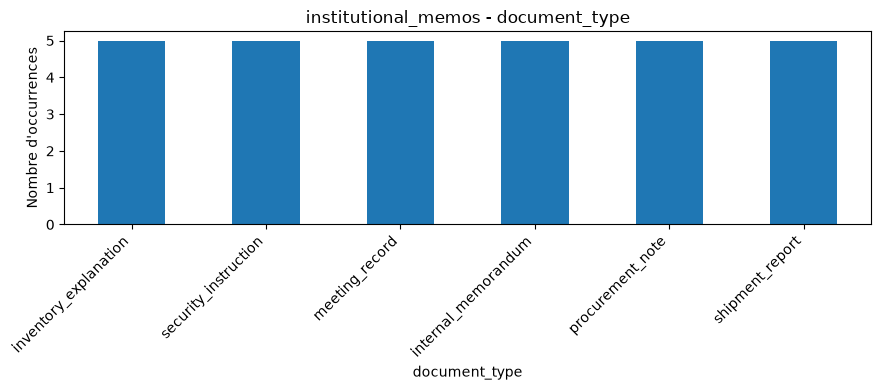

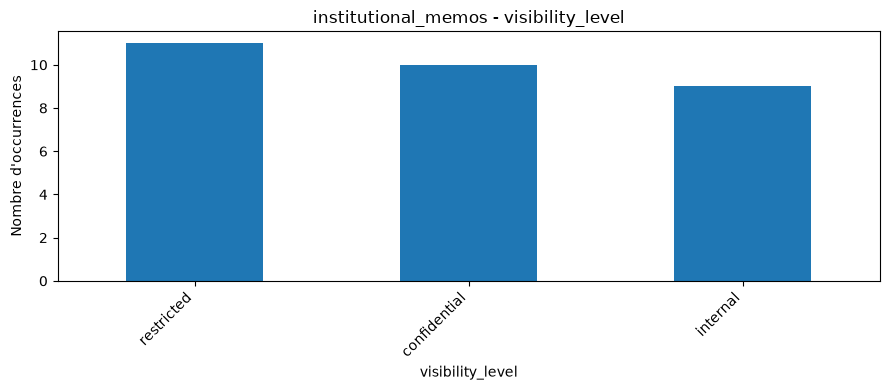

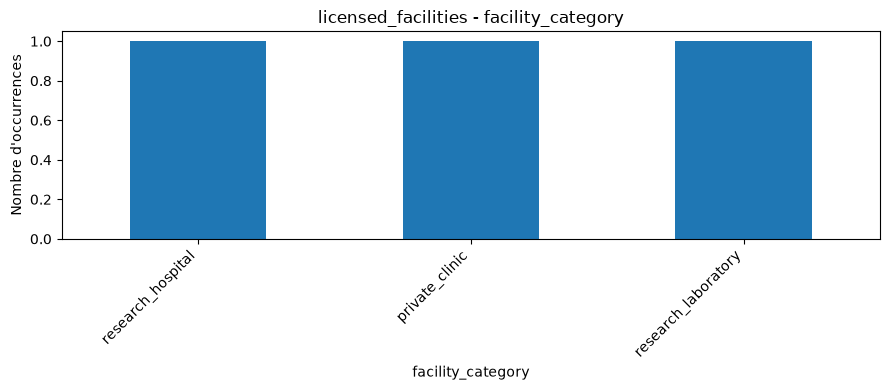

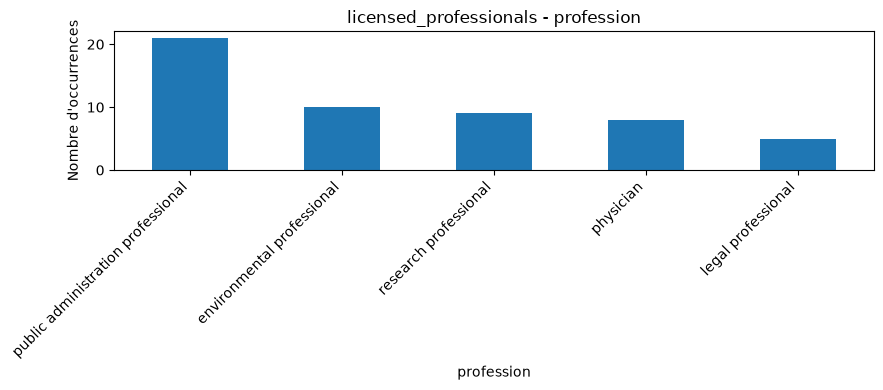

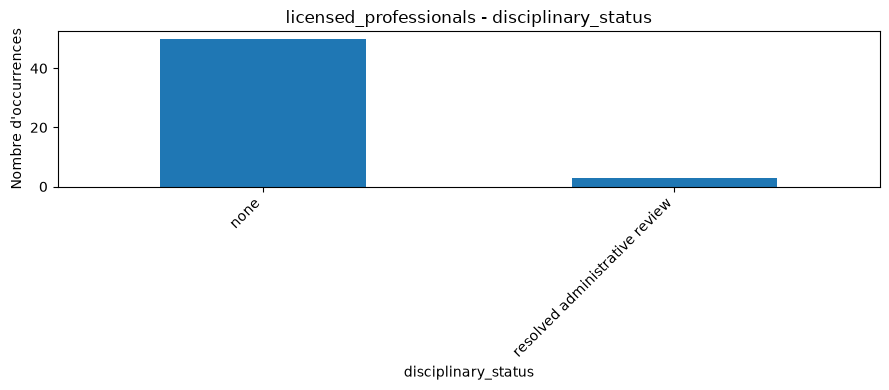

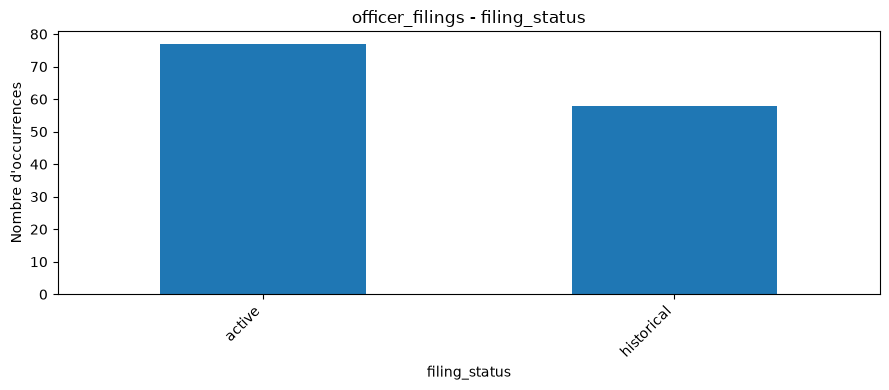

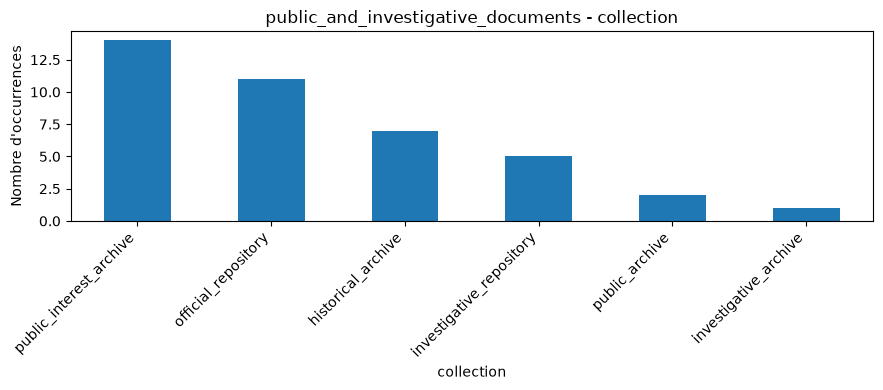

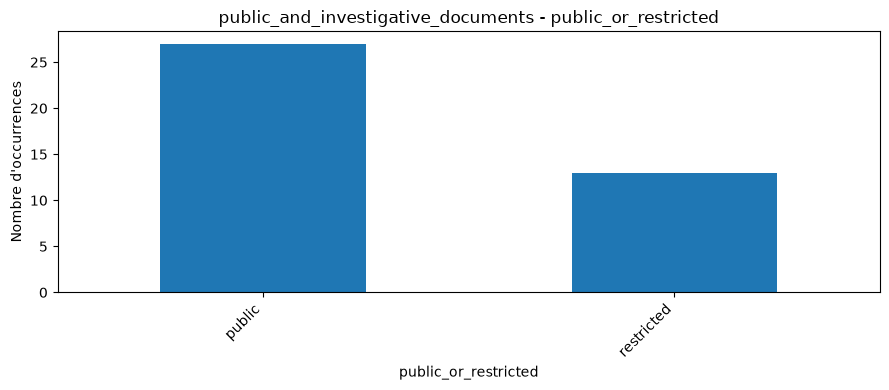

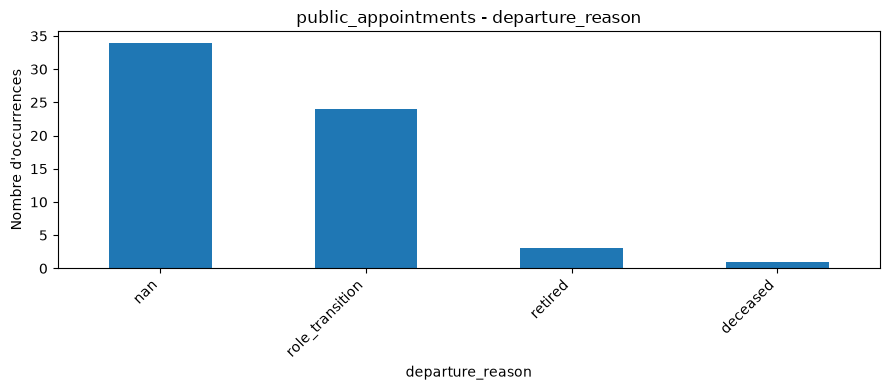

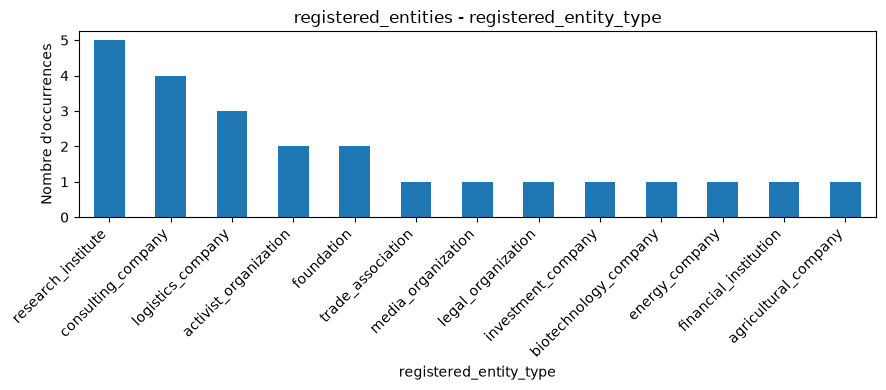

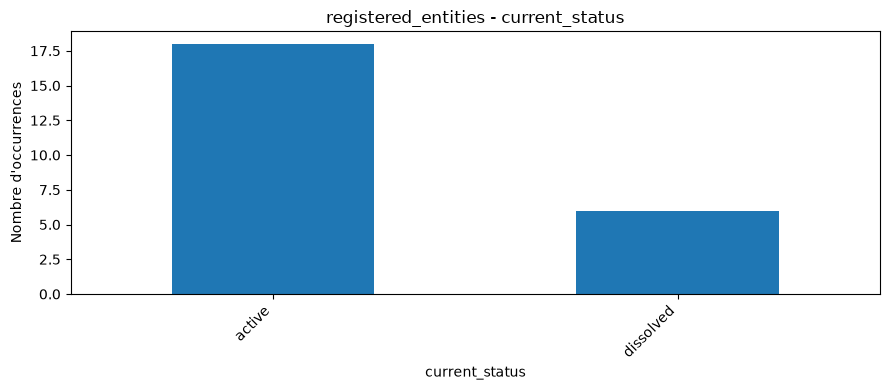

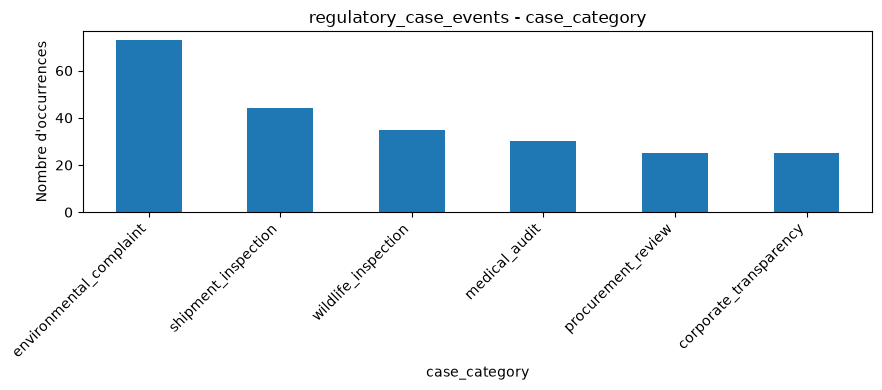

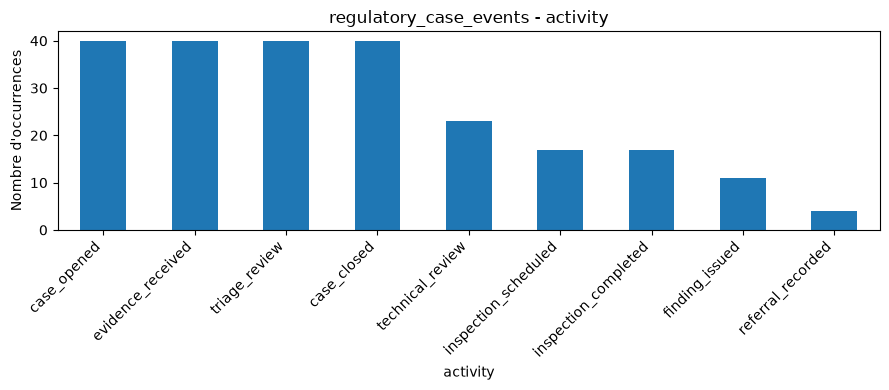

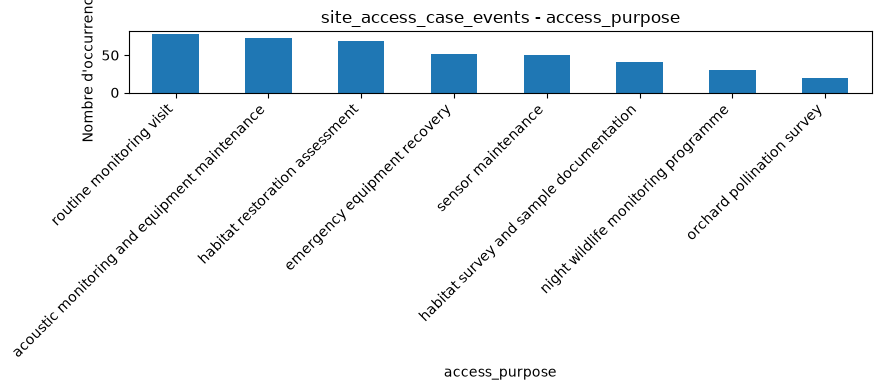

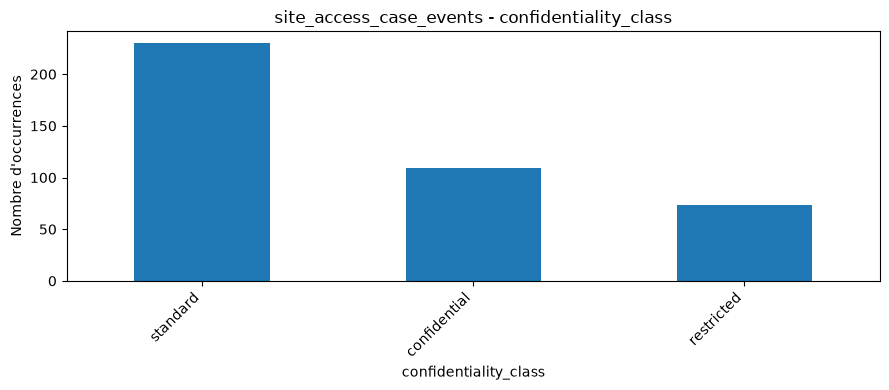

In [35]:
import matplotlib.pyplot as plt

colonnes_analyse = {
    "institutional_memos": ["document_type", "visibility_level"],
    "licensed_facilities": ["facility_category"],
    "licensed_professionals": ["profession", "disciplinary_status"],
    "officer_filings": ["filing_status"],
    "public_and_investigative_documents": ["collection", "public_or_restricted"],
    "public_appointments": ["departure_reason"],
    "registered_entities": ["registered_entity_type", "current_status"],
    "regulatory_case_events": ["case_category", "activity"],
    "site_access_case_events": ["access_purpose", "confidentiality_class"]
}

for nom, colonnes in colonnes_analyse.items():

    df = donnees_clean[nom]

    for col in colonnes:

        frequences = df[col].value_counts(dropna=False)

        plt.figure(figsize=(9, 4))
        frequences.plot(kind="bar")

        plt.title(f"{nom} - {col}")
        plt.xlabel(col)
        plt.ylabel("Nombre d'occurrences")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

count      53.000000
mean     1968.075472
std        15.077810
min      1935.000000
25%      1960.000000
50%      1970.000000
75%      1978.000000
max      1993.000000
Name: recorded_birth_year, dtype: float64


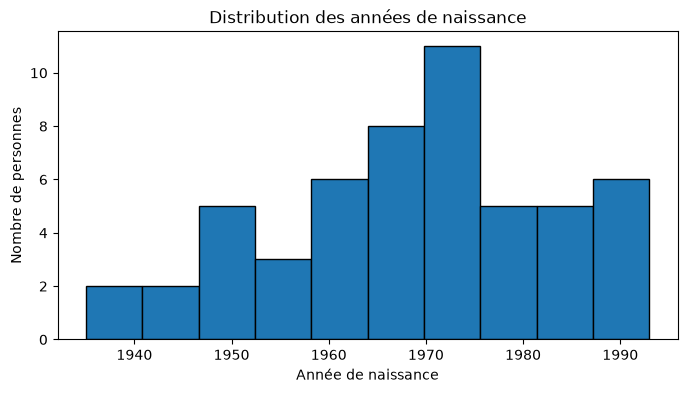

In [36]:
df = donnees_clean["public_appointments"]

print(df["recorded_birth_year"].describe())

plt.figure(figsize=(8, 4))

plt.hist(
    df["recorded_birth_year"].dropna(),
    bins=10,
    edgecolor="black"
)

plt.title("Distribution des années de naissance")
plt.xlabel("Année de naissance")
plt.ylabel("Nombre de personnes")
plt.show()

Nous avons représenté les distributions des principales variables catégorielles à l'aide de diagrammes en barres. Ces visualisations permettent d'observer les catégories les plus fréquentes dans chaque fichier et de mieux comprendre la composition des données.

Nous avons également étudié la distribution des années de naissance du fichier `public_appointments` à l'aide d'un histogramme.

Ces analyses descriptives nous permettront d'identifier les caractéristiques générales des données et de sélectionner les variables pertinentes pour les analyses suivantes.

### 4.1. Interprétation des statistiques descriptives

Nous avons étudié la répartition des principales variables catégorielles des 9 fichiers à l'aide de diagrammes en barres.

Dans `institutional_memos`, les 6 types de documents sont répartis de manière égale, avec 5 documents par catégorie. Les niveaux de visibilité sont également relativement équilibrés : 11 documents restreints, 10 confidentiels et 9 internes.

Le fichier `licensed_facilities` contient seulement 3 établissements de catégories différentes : un hôpital de recherche, une clinique privée et un laboratoire de recherche.

Dans `licensed_professionals`, les professionnels de l'administration publique sont les plus représentés (21 sur 53). La majorité des professionnels ne présentent aucun antécédent disciplinaire enregistré (50 sur 53).

Dans `officer_filings`, nous observons 77 enregistrements actifs et 58 historiques.

Concernant `public_and_investigative_documents`, la majorité des documents sont publics (27 sur 40), contre 13 documents restreints. Les collections les plus représentées sont `public_interest_archive` et `official_repository`.

Dans `public_appointments`, 34 enregistrements ne renseignent pas de motif de départ. Parmi les motifs renseignés, les transitions de fonction sont les plus fréquentes (24 occurrences).

Dans `registered_entities`, les instituts de recherche, les entreprises de conseil et les entreprises de logistique sont les catégories les plus représentées. La majorité des organisations sont actives (18 sur 24).

Dans `regulatory_case_events`, les plaintes environnementales constituent la catégorie la plus fréquente (73 événements), suivies des inspections de cargaisons (44 événements) et des inspections liées à la faune (35 événements).

Dans `site_access_case_events`, les motifs d'accès les plus fréquents concernent les visites de surveillance, la maintenance d'équipements acoustiques et l'évaluation de la restauration des habitats. Concernant la confidentialité, 230 événements sont classés `standard`, 109 `confidential` et 73 `restricted`.

Enfin, l'histogramme des années de naissance montre une concentration des observations autour des années 1960 à 1980, avec une médiane de 1970.

Ces résultats nous permettent de mieux comprendre la composition des données. Nous observons notamment la présence de documents restreints, d'activités de surveillance environnementale et d'inspections. Cependant, ces fréquences ne suffisent pas à établir des liens entre les événements. Des analyses complémentaires seront nécessaires.

### 4.2. Analyse des corrélations

Le cours présente les coefficients de Pearson et de Spearman pour mesurer les relations entre variables numériques.

Cependant, nos fichiers contiennent principalement des variables catégorielles, des identifiants, des dates et des textes.

Les seules variables numériques identifiées sont les coordonnées géographiques des établissements et les années de naissance des personnes nommées.

Nous avons donc choisi de ne pas calculer de corrélations entre ces variables, car elles ne permettent pas de répondre directement à notre problématique.

Nous privilégierons dans les prochaines étapes l'étude des relations entre organisations, documents, événements et périodes.

## 5. Ordonner et regrouper les données

Nous allons chercher à identifier des groupes d'observations présentant des caractéristiques similaires.

Pour cela, nous utiliserons les méthodes de similarité et de clustering.

Nous commençons par le fichier `site_access_case_events`, qui contient des informations sur les demandes d'accès aux sites, leurs motifs, leurs niveaux de confidentialité et leurs différents statuts.

L'objectif est de déterminer si certaines demandes d'accès présentent des caractéristiques communes et si certains groupes se distinguent des autres.

### 5.1. Examiner les variables disponibles

In [37]:
df = donnees_clean["site_access_case_events"].copy()

print("Dimensions :", df.shape)
print("\nColonnes disponibles :")
print(df.columns.tolist())

display(df.head())

Dimensions : (412, 15)

Colonnes disponibles :
['access_event_id', 'access_case_number', 'site_code', 'event_time', 'activity', 'requesting_organization_name', 'requesting_registration_number', 'authorizing_agency', 'authorized_person_name', 'access_purpose', 'equipment_category', 'previous_status', 'new_status', 'confidentiality_class', 'outcome']


,access_event_id,access_case_number,site_code,event_time,activity,requesting_organization_name,requesting_registration_number,authorizing_agency,authorized_person_name,access_purpose,equipment_category,previous_status,new_status,confidentiality_class,outcome
0,ACE-000001,ACC-2018-0001,TMB-NAC,2018-01-15 09:00:00,request_submitted,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Bela Ferran,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,draft,submitted,restricted,request logged
1,ACE-000002,ACC-2018-0001,TMB-NAC,2018-01-21 09:00:00,technical_review,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Kellan Orell,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,submitted,technical_review,restricted,technical review completed
2,ACE-000003,ACC-2018-0001,TMB-NAC,2018-01-26 09:00:00,wildlife_review,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Jalen Quorin,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,technical_review,wildlife_review,restricted,wildlife conditions recorded
3,ACE-000004,ACC-2018-0001,TMB-NAC,2018-01-30 09:00:00,security_review,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Jalen Zorin,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,wildlife_review,security_review,restricted,site-security conditions recorded
4,ACE-000005,ACC-2018-0001,TMB-NAC,2018-02-05 09:00:00,authorization_granted,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Xara Lask,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,security_review,authorized,restricted,authorization issued


### 5.2. Regroupement des événements par dossier

Le fichier `site_access_case_events` contient 412 lignes correspondant aux différentes étapes des demandes d'accès aux sites.

Nous avons remarqué qu'un même numéro de dossier (`access_case_number`) apparaît plusieurs fois, car chaque ligne représente un événement du processus.

Afin de comparer les demandes d'accès entre elles, nous avons décidé de regrouper les événements par numéro de dossier.

Nous obtiendrons ainsi une ligne par demande d'accès, avec les informations nécessaires pour effectuer le clustering.

In [38]:
#Vérifier le nombre de dossiers différents
df = donnees_clean["site_access_case_events"].copy()

print("Nombre d'événements :", len(df))
print("Nombre de dossiers différents :", df["access_case_number"].nunique())

print("\nNombre d'événements par dossier :")
display(df["access_case_number"].value_counts().head(15))

Nombre d'événements : 412
Nombre de dossiers différents : 60

Nombre d'événements par dossier :


access_case_number
ACC-2023-0013    10
ACC-2021-0010     9
ACC-2024-0015     9
ACC-2018-0001     8
ACC-2018-0002     8
ACC-2018-0003     8
ACC-2019-0006     8
ACC-2020-0007     8
ACC-2020-0008     8
ACC-2021-0009     8
ACC-2023-0012     8
ACC-2024-0016     8
ACC-2025-0017     8
ACC-2025-0018     8
ACC-2019-0004     7
Name: count, dtype: int64

In [39]:
#Vérifier que les informations sont constantes dans chaque dossier
colonnes = [
    "site_code",
    "requesting_organization_name",
    "requesting_registration_number",
    "authorizing_agency",
    "access_purpose",
    "equipment_category",
    "confidentiality_class"
]

for col in colonnes:
    variations = (
        df.groupby("access_case_number")[col]
        .nunique(dropna=False)
    )

    print(f"{col} : {(variations > 1).sum()} dossiers avec plusieurs valeurs")

site_code : 0 dossiers avec plusieurs valeurs
requesting_organization_name : 0 dossiers avec plusieurs valeurs
requesting_registration_number : 0 dossiers avec plusieurs valeurs
authorizing_agency : 0 dossiers avec plusieurs valeurs
access_purpose : 0 dossiers avec plusieurs valeurs
equipment_category : 0 dossiers avec plusieurs valeurs
confidentiality_class : 0 dossiers avec plusieurs valeurs


Le fichier `site_access_case_events` contient 412 événements répartis dans 60 dossiers différents. Certains dossiers comportent davantage d'étapes que d'autres, avec jusqu'à 10 événements pour le dossier `ACC-2023-0013`.

Nous avons vérifié que les informations concernant le site, l'organisation demandeuse, l'agence d'autorisation, le motif d'accès, l'équipement et la confidentialité restent constantes au sein de chaque dossier.

Aucune variation n'a été détectée dans ces colonnes. Nous pouvons donc regrouper les événements par numéro de dossier en conservant ces informations.

Cette transformation permettra de comparer les 60 demandes d'accès entre elles plutôt que leurs 412 événements individuels.

### 5.3. Création d'une table par dossier

In [40]:
# Regrouper les événements par dossier

df_dossiers = (
    df.sort_values("event_time")
      .groupby("access_case_number", as_index=False)
      .agg(
          site_code=("site_code", "first"),
          requesting_organization_name=("requesting_organization_name", "first"),
          requesting_registration_number=("requesting_registration_number", "first"),
          authorizing_agency=("authorizing_agency", "first"),
          access_purpose=("access_purpose", "first"),
          equipment_category=("equipment_category", "first"),
          confidentiality_class=("confidentiality_class", "first"),
          nombre_evenements=("access_event_id", "count"),
          date_debut=("event_time", "min"),
          date_fin=("event_time", "max")
      )
)

print("Dimensions :", df_dossiers.shape)
display(df_dossiers.head())

Dimensions : (60, 11)


,access_case_number,site_code,requesting_organization_name,requesting_registration_number,authorizing_agency,access_purpose,equipment_category,confidentiality_class,nombre_evenements,date_debut,date_fin
0,ACC-2015-0029,KNT-DMJ,Nordhaven Maritime Safety Agency,NaN,Kintara Cave and Pollinator Authority,emergency equipment recovery,camera equipment,standard,7,2015-11-01 09:00:00,2015-11-18 09:00:00
1,ACC-2015-0034,KNT-VXR,Orison Facility Management,REG-VLN-20015,Kintara Cave and Pollinator Authority,sensor maintenance,camera equipment,standard,6,2015-02-15 09:00:00,2015-03-04 09:00:00
2,ACC-2016-0046,AVL-RBC,Kintara Emergency Response Office,NaN,Avelora Agricultural Resilience Agency,orchard pollination survey,acoustic monitoring equipment,standard,6,2016-02-17 09:00:00,2016-03-05 09:00:00
3,ACC-2017-0025,KNT-VLB,Valenne Laboratory Materials,REG-VLN-20009,Kintara Cave and Pollinator Authority,routine monitoring visit,acoustic monitoring equipment,confidential,6,2017-08-01 09:00:00,2017-08-18 09:00:00
4,ACC-2017-0039,AVL-NFR,Juniper Community Health Foundation,REG-KNT-20025,Avelora Agricultural Resilience Agency,emergency equipment recovery,maintenance tools,confidential,7,2017-02-10 09:00:00,2017-02-27 09:00:00


Le regroupement a permis d'obtenir une table de 60 dossiers et 11 colonnes.

Chaque ligne représente désormais une demande d'accès, avec son site, son organisation demandeuse, son motif d'accès, ses équipements, son niveau de confidentialité, le nombre d'événements et les dates de début et de fin.

Cette nouvelle structure nous permet de comparer les demandes d'accès entre elles sans compter plusieurs fois les événements appartenant au même dossier.

Nous allons maintenant préparer les variables catégorielles pour calculer les similarités entre les dossiers.

### 5.4. Sélection des variables pour le clustering

Après avoir regroupé les événements par dossier, nous avons sélectionné quatre variables pour comparer les demandes d'accès : `site_code`, `access_purpose`, `equipment_category` et `confidentiality_class`.

Ces variables permettent de comparer les dossiers selon leur localisation, leur motif d'accès, les équipements utilisés et leur niveau de confidentialité.

Les autres variables sont conservées dans la table initiale pour les analyses suivantes, mais ne seront pas utilisées directement dans le calcul des distances.

In [41]:
# Sélection des variables pour le clustering
variables_clustering = [
    "site_code",
    "access_purpose",
    "equipment_category",
    "confidentiality_class"
]

X = df_dossiers[variables_clustering].copy()

display(X.head())

,site_code,access_purpose,equipment_category,confidentiality_class
0,KNT-DMJ,emergency equipment recovery,camera equipment,standard
1,KNT-VXR,sensor maintenance,camera equipment,standard
2,AVL-RBC,orchard pollination survey,acoustic monitoring equipment,standard
3,KNT-VLB,routine monitoring visit,acoustic monitoring equipment,confidential
4,AVL-NFR,emergency equipment recovery,maintenance tools,confidential


### 5.5. Encodage des variables catégorielles

Les quatre variables sélectionnées sont des variables nominales non ordonnées.

Nous avons donc choisi d'utiliser l'encodage One-Hot, présenté dans le CM2, afin de transformer chaque catégorie en variable binaire (0 ou 1).

Cette transformation permet de représenter numériquement les caractéristiques des dossiers en vue des analyses de similarité et de clustering.

In [42]:
# Encodage One-Hot

X_encoded = pd.get_dummies(X, dtype=int)

print("Dimensions avant encodage :", X.shape)
print("Dimensions après encodage :", X_encoded.shape)

display(X_encoded.head())

Dimensions avant encodage : (60, 4)
Dimensions après encodage : (60, 67)


,site_code_AVL-ABG,site_code_AVL-ARU,site_code_AVL-BVM,site_code_AVL-BWK,site_code_AVL-DER,site_code_AVL-ECJ,site_code_AVL-FNM,site_code_AVL-FNQ,site_code_AVL-GRB,site_code_AVL-HTY,...,access_purpose_sensor maintenance,equipment_category_acoustic and camera equipment,equipment_category_acoustic monitoring equipment,equipment_category_camera equipment,equipment_category_maintenance tools,equipment_category_portable monitoring and cold-storage equipment,equipment_category_protective field equipment,confidentiality_class_confidential,confidentiality_class_restricted,confidentiality_class_standard
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0


Après l'encodage One-Hot, nous obtenons une matrice de 60 lignes et 67 colonnes, contre 60 lignes et 4 colonnes initialement.

Chaque catégorie est désormais représentée par une variable binaire indiquant sa présence (1) ou son absence (0) dans un dossier.

Cette transformation permet de représenter numériquement les demandes d'accès pour les analyses suivantes.

### 5.6. Calcul des distances entre les dossiers

Nous avons choisi la distance de Hamming pour comparer les demandes d'accès.

Cette distance mesure la proportion de caractéristiques différentes entre deux dossiers.

Une distance de 0 signifie que les dossiers possèdent les mêmes valeurs pour les quatre variables sélectionnées. Une distance de 1 signifie qu'ils diffèrent sur toutes ces variables.

Nous utilisons les quatre variables d'origine afin que chaque caractéristique ait le même poids dans le calcul.

In [43]:
from scipy.spatial.distance import pdist, squareform

# Conversion des catégories en codes numériques
X_codes = X.apply(lambda col: col.astype("category").cat.codes)

# Calcul de la distance de Hamming
distances = squareform(
    pdist(X_codes.to_numpy(), metric="hamming")
)

matrice_distances = pd.DataFrame(
    distances,
    index=df_dossiers["access_case_number"],
    columns=df_dossiers["access_case_number"]
)

print("Dimensions :", matrice_distances.shape)

display(matrice_distances.iloc[:10, :10])

Dimensions : (60, 60)


access_case_number,ACC-2015-0029,ACC-2015-0034,ACC-2016-0046,ACC-2017-0025,ACC-2017-0039,ACC-2017-0042,ACC-2017-0044,ACC-2018-0001,ACC-2018-0002,ACC-2018-0003
access_case_number,,,,,,,,,,
ACC-2015-0029,0.00,0.50,0.75,1.00,0.75,0.75,0.75,1.00,1.00,1.00
ACC-2015-0034,0.50,0.00,0.75,1.00,1.00,0.75,0.75,1.00,1.00,1.00
ACC-2016-0046,0.75,0.75,0.00,0.75,1.00,0.75,0.75,1.00,1.00,1.00
ACC-2017-0025,1.00,1.00,0.75,0.00,0.75,0.75,1.00,1.00,0.75,1.00
ACC-2017-0039,0.75,1.00,1.00,0.75,0.00,1.00,1.00,1.00,0.75,1.00
ACC-2017-0042,0.75,0.75,0.75,0.75,1.00,0.00,0.50,1.00,1.00,0.75
ACC-2017-0044,0.75,0.75,0.75,1.00,1.00,0.50,0.00,1.00,1.00,0.75
ACC-2018-0001,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.75,0.75
ACC-2018-0002,1.00,1.00,1.00,0.75,0.75,1.00,1.00,0.75,0.00,1.00


Pour calculer la distance de Hamming, nous avons converti les catégories textuelles en codes numériques.

Cette conversion ne crée aucun ordre entre les catégories : les nombres servent uniquement à les identifier.

Nous calculons ensuite la proportion de caractéristiques différentes entre chaque paire de dossiers.

### 5.7. Visualisation de la matrice de distances

Afin de visualiser les similarités entre les 60 dossiers, nous représentons la matrice de distances sous forme de carte de chaleur.

Les valeurs proches de 0 correspondent à des dossiers très similaires sur les quatre variables sélectionnées, tandis que les valeurs proches de 1 correspondent à des dossiers très différents.

Cette représentation permet d'identifier visuellement d'éventuels groupes de dossiers proches.

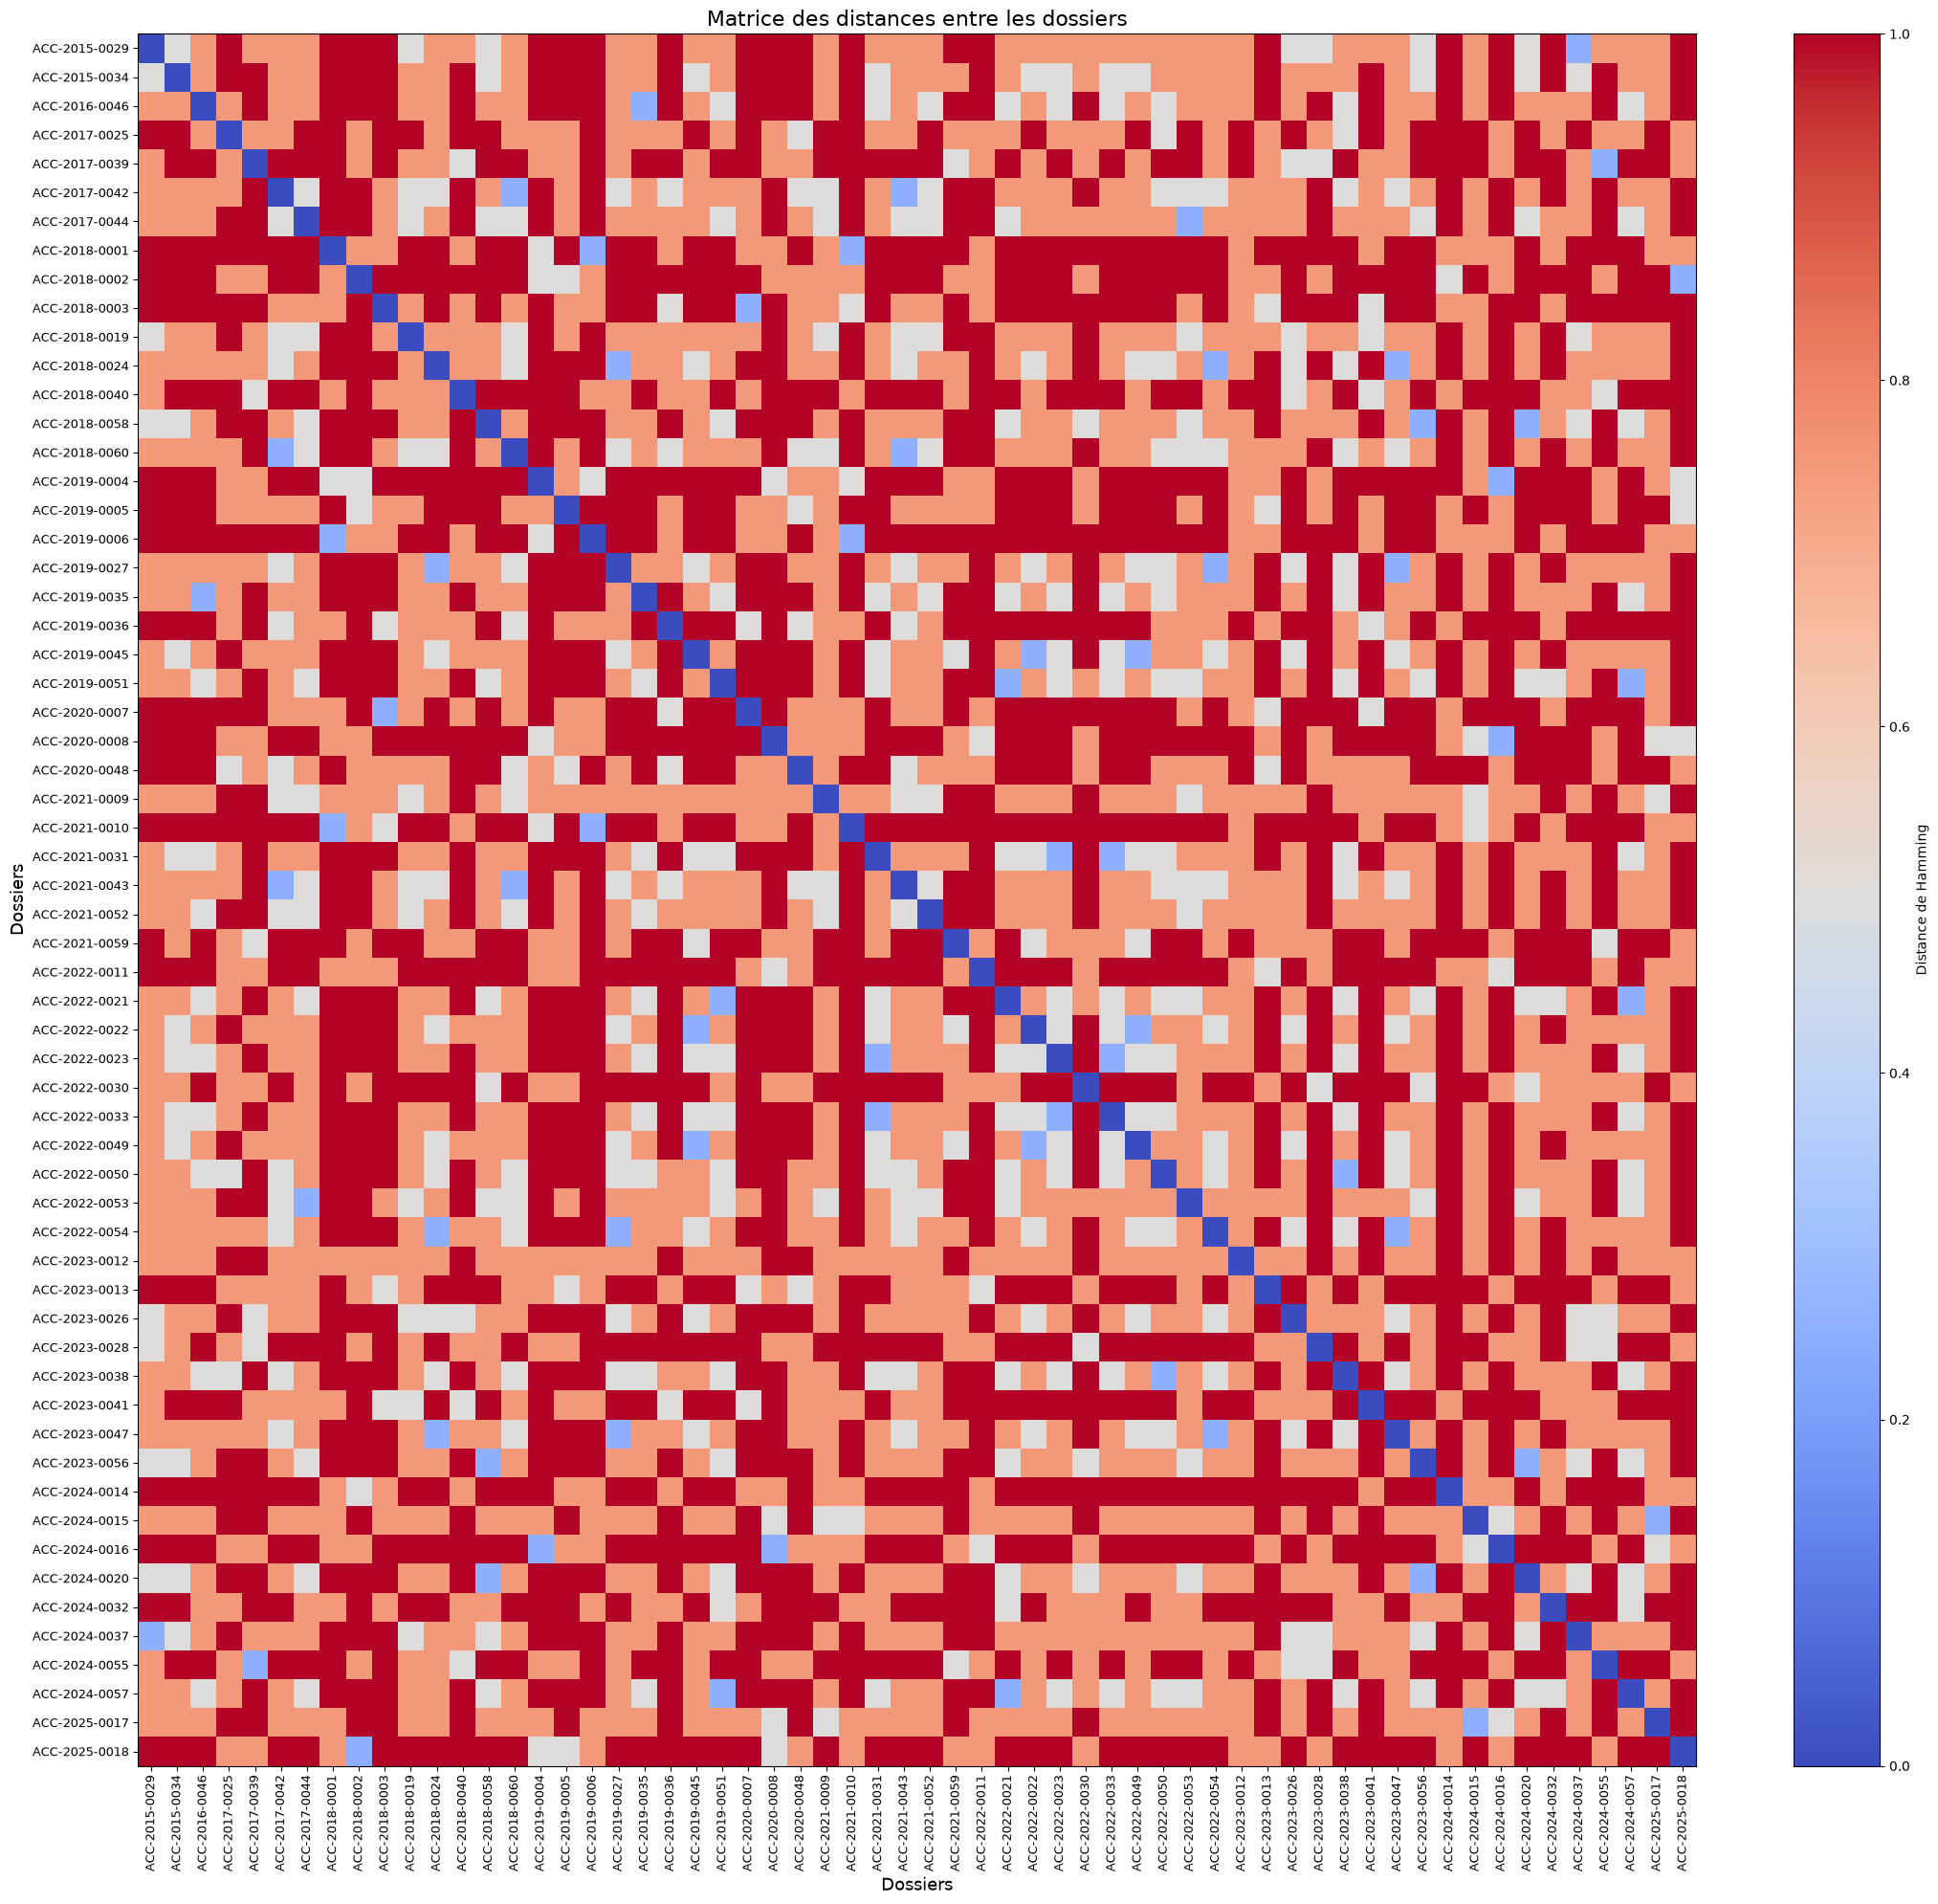

In [44]:
plt.figure(figsize=(22, 20))

plt.imshow(
    matrice_distances,
    cmap="coolwarm",
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Distance de Hamming")

plt.title("Matrice des distances entre les dossiers", fontsize=16)
plt.xlabel("Dossiers", fontsize=13)
plt.ylabel("Dossiers", fontsize=13)

plt.xticks(
    range(len(matrice_distances.columns)),
    matrice_distances.columns,
    rotation=90,
    fontsize=9
)

plt.yticks(
    range(len(matrice_distances.index)),
    matrice_distances.index,
    fontsize=9
)

plt.tight_layout()
plt.show()

### 5.8. Clustering hiérarchique

Après avoir calculé les distances de Hamming entre les 60 dossiers, nous allons appliquer un clustering hiérarchique ascendant.

Cette méthode consiste à regrouper progressivement les dossiers les plus similaires, puis à fusionner les groupes obtenus.

Nous utiliserons la matrice de distances précédemment calculée afin de construire un dendrogramme et d'observer les regroupements possibles.

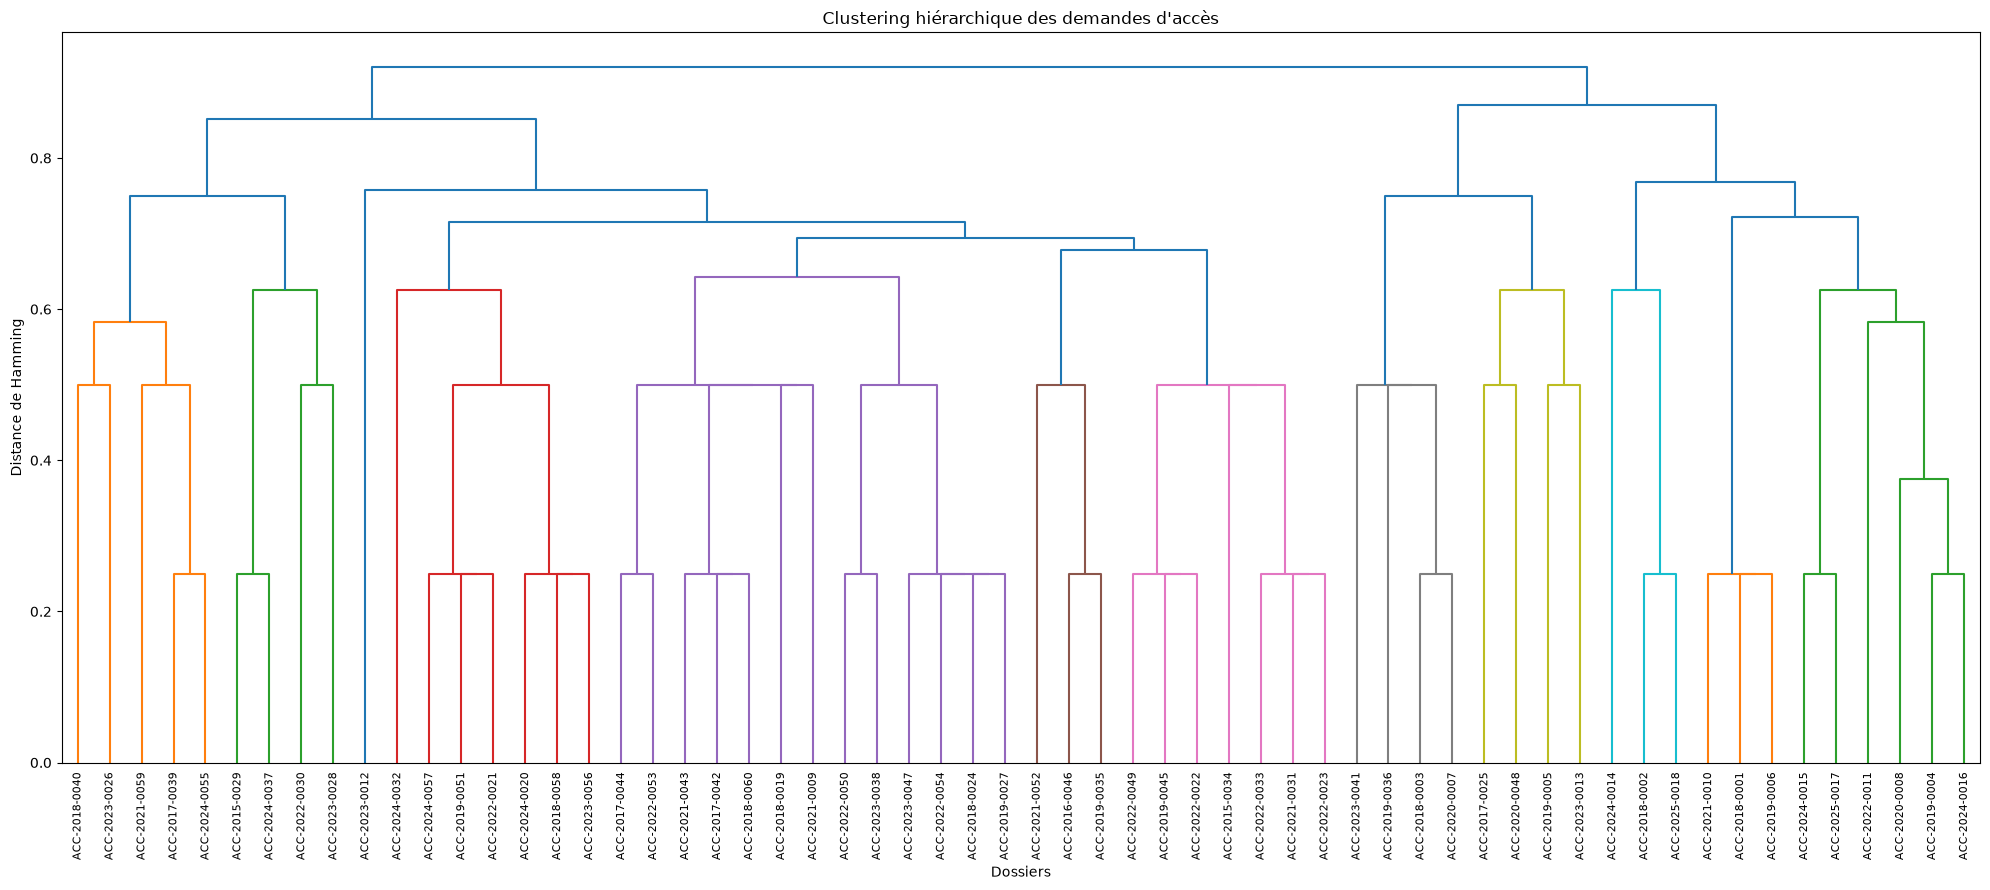

In [45]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Clustering hiérarchique à partir des distances de Hamming
Z = linkage(
    pdist(X_codes.to_numpy(), metric="hamming"),
    method="average"
)

# Dendrogramme
plt.figure(figsize=(20, 9))

dendrogram(
    Z,
    labels=df_dossiers["access_case_number"].values,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title("Clustering hiérarchique des demandes d'accès")
plt.xlabel("Dossiers")
plt.ylabel("Distance de Hamming")

plt.tight_layout()
plt.show()

Le dendrogramme représente les regroupements successifs des 60 dossiers selon leur distance de Hamming.

Nous observons plusieurs petits groupes de dossiers similaires, dont certains fusionnent à une distance de 0,25, ce qui indique qu'ils partagent plusieurs caractéristiques.

Les regroupements plus importants apparaissent à des distances plus élevées, ce qui traduit des différences plus importantes entre les groupes.

Cette représentation suggère l'existence de plusieurs groupes de demandes d'accès. Nous allons maintenant déterminer un nombre de clusters afin de les analyser.

In [46]:
from scipy.cluster.hierarchy import fcluster

for seuil in [0.5, 0.6, 0.7, 0.8]:
    clusters = fcluster(Z, t=seuil, criterion="distance")
    print(f"Seuil {seuil} : {len(set(clusters))} clusters")

Seuil 0.5 : 20 clusters
Seuil 0.6 : 18 clusters
Seuil 0.7 : 10 clusters
Seuil 0.8 : 4 clusters


Afin de déterminer un seuil de découpage pertinent, nous avons testé plusieurs distances : 0,5, 0,6, 0,7 et 0,8.

Nous obtenons respectivement 20, 18, 10 et 4 clusters.

Lorsque le seuil augmente, les groupes fusionnent progressivement. Un seuil faible produit de nombreux petits groupes, tandis qu'un seuil élevé conduit à des regroupements plus importants.

Nous allons examiner la composition des clusters afin de choisir un découpage permettant de distinguer des groupes cohérents et interprétables.

In [47]:
for seuil in [0.7, 0.8]:
    clusters = fcluster(Z, t=seuil, criterion="distance")

    print(f"\n--- Seuil {seuil} ---")

    print(
        pd.Series(clusters)
        .value_counts()
        .sort_index()
    )


--- Seuil 0.7 ---
1      5
2      4
3      7
4     23
5      1
6      4
7      4
8      3
9      3
10     6
Name: count, dtype: int64

--- Seuil 0.8 ---
1     9
2    31
3     8
4    12
Name: count, dtype: int64


Nous avons comparé la répartition des dossiers pour deux seuils de découpage du dendrogramme.

Avec un seuil de 0,7, nous obtenons 10 clusters, dont un contenant 23 dossiers et un autre contenant un seul dossier.

Avec un seuil de 0,8, nous obtenons 4 clusters comprenant entre 8 et 31 dossiers.

Le seuil de 0,7 permet de distinguer davantage de groupes, tandis que celui de 0,8 produit des groupes plus larges.

Nous allons examiner les caractéristiques des clusters obtenus avec le seuil de 0,7 afin de déterminer si ces regroupements sont pertinents pour notre analyse.

In [48]:
# Attribuer un cluster à chaque dossier
df_dossiers["cluster"] = fcluster(Z, t=0.7, criterion="distance")

# Examiner les niveaux de confidentialité par cluster
tableau = pd.crosstab(
    df_dossiers["cluster"],
    df_dossiers["confidentiality_class"]
)

display(tableau)

confidentiality_class,confidential,restricted,standard
cluster,,,
1,3,1,1
2,2,0,2
3,0,1,6
4,0,0,23
5,0,0,1
6,0,4,0
7,4,0,0
8,2,1,0
9,0,3,0


In [49]:
# Examiner les dossiers des clusters 6 et 9
display(
    df_dossiers[
        df_dossiers["cluster"].isin([6, 9])
    ][[
        "access_case_number",
        "cluster",
        "requesting_organization_name",
        "site_code",
        "access_purpose",
        "confidentiality_class"
    ]]
)

,access_case_number,cluster,requesting_organization_name,site_code,access_purpose,confidentiality_class
7,ACC-2018-0001,9,Horizon Field Research Cooperative,TMB-NAC,acoustic monitoring and equipment maintenance,restricted
9,ACC-2018-0003,6,Horizon Field Research Cooperative,AVL-MAR,habitat survey and sample documentation,restricted
17,ACC-2019-0006,9,Horizon Field Research Cooperative,AVL-VEL,acoustic monitoring and equipment maintenance,restricted
20,ACC-2019-0036,6,Senna Agricultural Research Centre,KNT-BME,routine monitoring visit,restricted
23,ACC-2020-0007,6,Horizon Field Research Cooperative,KNT-SEN,habitat survey and sample documentation,restricted
27,ACC-2021-0010,9,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,restricted
47,ACC-2023-0041,6,Quartz Data Hosting,AVL-GRB,emergency equipment recovery,restricted


In [50]:
pd.crosstab(
    df_dossiers["requesting_organization_name"],
    df_dossiers["confidentiality_class"]
)

confidentiality_class,confidential,restricted,standard
requesting_organization_name,,,
Auric Medical Supplies,0,0,2
Avelora Civil Service College,0,0,1
Avelora Food Standards Office,1,0,1
Avelora Orchard Export Union,0,0,2
Blue Heron Monitoring Cooperative,0,0,1
Civic Health Purchasing Network,0,0,2
Dune Agricultural Machinery,0,1,0
Garnet Scientific Instruments,0,0,1
Horizon Field Research Cooperative,8,6,4


### Interprétation des résultats

L'analyse des clusters met en évidence plusieurs groupes de dossiers partageant des caractéristiques similaires.

Nous avons notamment observé que l'organisation Horizon Field Research Cooperative possède 18 dossiers, dont 8 confidentiels, 6 restreints et 4 standards.

Cette organisation se distingue par le nombre de dossiers présents dans notre jeu de données et par leur niveau de confidentialité.

Cependant, la confidentialité étant déjà utilisée pour construire les clusters, ces regroupements ne constituent pas à eux seuls des anomalies.

Une analyse complémentaire des relations entre les organisations et les événements serait nécessaire pour déterminer si ces observations sont pertinentes pour notre enquête.

## 6. Recherche de patterns et d'anomalies

In [51]:
# Sélection des variables utiles
dossiers_cm4 = donnees_clean["site_access_case_events"][
    ["access_case_number", "access_purpose",
     "equipment_category", "confidentiality_class"]
]

# Conserver une ligne par dossier
dossiers_cm4 = dossiers_cm4.drop_duplicates(
    subset=["access_case_number"]
)

print("Nombre de dossiers :", len(dossiers_cm4))

display(dossiers_cm4.head())

Nombre de dossiers : 60


,access_case_number,access_purpose,equipment_category,confidentiality_class
0,ACC-2018-0001,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted
8,ACC-2018-0002,night wildlife monitoring programme,portable monitoring and cold-storage equipment,confidential
16,ACC-2018-0003,habitat survey and sample documentation,protective field equipment,restricted
24,ACC-2019-0004,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,confidential
31,ACC-2019-0005,night wildlife monitoring programme,protective field equipment,confidential


In [52]:
# Vérifier si les caractéristiques changent au sein d'un même dossier

colonnes = ["access_purpose", "equipment_category", "confidentiality_class"]

verification = donnees_clean["site_access_case_events"].groupby(
    "access_case_number"
)[colonnes].nunique(dropna=False)

# Repérer les dossiers ayant des valeurs différentes
differences = verification[(verification > 1).any(axis=1)]

print("Nombre de dossiers avec des caractéristiques différentes :", len(differences))

display(differences)

Nombre de dossiers avec des caractéristiques différentes : 0


,access_purpose,equipment_category,confidentiality_class
access_case_number,,,


### 6.2. Matrice de cooccurrences

Nous construisons une matrice de cooccurrences afin d'étudier
les associations entre les motifs d'accès et les niveaux
de confidentialité des 60 dossiers.

In [53]:
# Matrice de cooccurrences
matrice = pd.crosstab(
    dossiers_cm4["access_purpose"],
    dossiers_cm4["confidentiality_class"]
)

display(matrice)

confidentiality_class,confidential,restricted,standard
access_purpose,,,
acoustic monitoring and equipment maintenance,3,3,3
emergency equipment recovery,3,2,4
habitat restoration assessment,1,1,8
habitat survey and sample documentation,2,2,1
night wildlife monitoring programme,3,1,0
orchard pollination survey,0,0,3
routine monitoring visit,2,1,9
sensor maintenance,1,0,7


In [54]:
# Calcul des pourcentages par ligne
matrice_pct = matrice.div(matrice.sum(axis=1), axis=0) * 100

display(matrice_pct.round(1))

confidentiality_class,confidential,restricted,standard
access_purpose,,,
acoustic monitoring and equipment maintenance,33.3,33.3,33.3
emergency equipment recovery,33.3,22.2,44.4
habitat restoration assessment,10.0,10.0,80.0
habitat survey and sample documentation,40.0,40.0,20.0
night wildlife monitoring programme,75.0,25.0,0.0
orchard pollination survey,0.0,0.0,100.0
routine monitoring visit,16.7,8.3,75.0
sensor maintenance,12.5,0.0,87.5


### Interprétation des résultats

La matrice de cooccurrences permet d'observer les associations entre les motifs d'accès et les niveaux de confidentialité des 60 dossiers.

Nous remarquons que certains motifs sont davantage associés à des niveaux de confidentialité élevés. Par exemple, les 4 dossiers concernant la surveillance nocturne de la faune sont classés confidentiels (75 %) ou restreints (25 %). De même, 80 % des dossiers concernant la documentation d'échantillons sont confidentiels ou restreints.

À l'inverse, les visites de surveillance habituelles sont majoritairement standards (75 %).

Ces résultats montrent que le niveau de confidentialité varie selon le motif d'accès. Cependant, certains groupes contiennent peu de dossiers, ce qui limite les conclusions possibles.

Cette analyse nous permet d'identifier des dossiers intéressants à approfondir, notamment ceux concernant la surveillance de la faune et les échantillons.

### 6.3. Analyse des dossiers de surveillance nocturne

Nous examinons les dossiers de surveillance nocturne de la faune afin d'identifier les organisations et les sites concernés.

L'objectif est de déterminer si ces dossiers présentent des caractéristiques communes pouvant être utiles à notre enquête.

In [55]:
# Sélectionner les dossiers de surveillance nocturne
df = donnees_clean["site_access_case_events"]

dossiers = df[
    df["access_purpose"] == "night wildlife monitoring programme"
]

# Conserver une ligne par dossier
dossiers = dossiers.drop_duplicates(subset="access_case_number")

# Afficher les informations
display(dossiers[[
    "access_case_number",
    "requesting_organization_name",
    "site_code",
    "confidentiality_class"
]])

,access_case_number,requesting_organization_name,site_code,confidentiality_class
8,ACC-2018-0002,Horizon Field Research Cooperative,KNT-KES,confidential
31,ACC-2019-0005,Horizon Field Research Cooperative,KNT-LUM,confidential
104,ACC-2024-0014,Horizon Field Research Cooperative,KNT-KES,restricted
136,ACC-2025-0018,Horizon Field Research Cooperative,AVL-ORR,confidential


### Interprétation des résultats

L'analyse des dossiers de surveillance nocturne de la faune montre que les 4 dossiers concernent la même organisation, Horizon Field Research Cooperative.

Ces dossiers sont répartis sur trois sites différents, dont le site KNT-KES qui apparaît à deux reprises, en 2018 et 2024.

Les quatre dossiers sont classés confidentiels ou restreints.

Ces résultats montrent une association entre une même organisation, un motif d'accès et des niveaux de confidentialité élevés. Cependant, ils ne permettent pas de conclure à une activité inhabituelle.

Nous allons donc examiner les autres activités enregistrées sur ces sites afin de mieux comprendre les caractéristiques de ces dossiers.

### 6.4. Analyse des activités sur les sites identifiés

Nous examinons les autres dossiers associés aux trois sites précédemment identifiés afin de déterminer quelles organisations y interviennent et quels types d'activités y sont enregistrés.

In [56]:
# Récupérer les sites identifiés précédemment
sites = dossiers["site_code"].unique()

# Conserver une ligne par dossier
df_sites = df.drop_duplicates(subset="access_case_number")

# Sélectionner les dossiers associés à ces sites
resultats = df_sites[df_sites["site_code"].isin(sites)]

display(resultats[[
    "access_case_number",
    "requesting_organization_name",
    "site_code",
    "access_purpose",
    "confidentiality_class"
]].sort_values("site_code"))

,access_case_number,requesting_organization_name,site_code,access_purpose,confidentiality_class
54,ACC-2020-0008,Horizon Field Research Cooperative,AVL-ORR,acoustic monitoring and equipment maintenance,confidential
136,ACC-2025-0018,Horizon Field Research Cooperative,AVL-ORR,night wildlife monitoring programme,confidential
8,ACC-2018-0002,Horizon Field Research Cooperative,KNT-KES,night wildlife monitoring programme,confidential
62,ACC-2021-0009,Horizon Field Research Cooperative,KNT-KES,acoustic monitoring and equipment maintenance,standard
104,ACC-2024-0014,Horizon Field Research Cooperative,KNT-KES,night wildlife monitoring programme,restricted
31,ACC-2019-0005,Horizon Field Research Cooperative,KNT-LUM,night wildlife monitoring programme,confidential
86,ACC-2023-0012,Horizon Field Research Cooperative,KNT-LUM,habitat survey and sample documentation,standard


### Interprétation des résultats

L'analyse des trois sites identifiés révèle 7 dossiers concernant uniquement Horizon Field Research Cooperative.

Nous observons que les activités de surveillance nocturne de la faune sont associées à d'autres activités, notamment la maintenance d'équipements acoustiques et la documentation d'échantillons.

Les dossiers de surveillance nocturne sont tous confidentiels ou restreints, tandis que les autres activités présentent différents niveaux de confidentialité.

Ces résultats mettent en évidence des activités récurrentes sur plusieurs sites.

### 6.5. Détection d'anomalies

Nous cherchons à identifier les dossiers présentant un nombre
d'événements inhabituel.

Pour cela, nous commençons par calculer le nombre d'événements
associés à chaque dossier.

In [57]:
# Compter le nombre d'événements par dossier
nb_evenements = donnees_clean["site_access_case_events"].groupby(
    "access_case_number"
).size()

# Statistiques descriptives
print(nb_evenements.describe())

# Répartition du nombre d'événements
print(nb_evenements.value_counts().sort_index())

count    60.000000
mean      6.866667
std       1.111827
min       4.000000
25%       6.000000
50%       7.000000
75%       7.000000
max      10.000000
dtype: float64
4      2
5      4
6     12
7     28
8     11
9      2
10     1
Name: count, dtype: int64


In [58]:
# Calcul de l'IQR
Q1 = nb_evenements.quantile(0.25)
Q3 = nb_evenements.quantile(0.75)

IQR = Q3 - Q1

# Calcul des bornes
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# Recherche des valeurs aberrantes
anomalies = nb_evenements[
    (nb_evenements < borne_inf) |
    (nb_evenements > borne_sup)
]

print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)
print("Nombre de dossiers atypiques :", len(anomalies))

display(anomalies)

Borne inférieure : 4.5
Borne supérieure : 8.5
Nombre de dossiers atypiques : 5


access_case_number
ACC-2018-0019     4
ACC-2018-0040     4
ACC-2021-0010     9
ACC-2023-0013    10
ACC-2024-0015     9
dtype: int64

### Interprétation des résultats

La méthode IQR a permis d'identifier 5 dossiers atypiques parmi les 60 étudiés.

Deux dossiers contiennent seulement 4 événements, tandis que trois autres en contiennent 9 ou 10, alors que la médiane est de 7 événements.

Ces résultats montrent que certains dossiers s'écartent de la distribution habituelle. 

Nous allons donc examiner leurs caractéristiques afin de mieux comprendre ces différences.

In [59]:
# Sélectionner les dossiers atypiques
df = donnees_clean["site_access_case_events"]

dossiers_atypiques = df[
    df["access_case_number"].isin(anomalies.index)
]

# Conserver une ligne par dossier
dossiers_atypiques = dossiers_atypiques.drop_duplicates(
    subset="access_case_number"
)

# Afficher les caractéristiques
display(dossiers_atypiques[[
    "access_case_number",
    "requesting_organization_name",
    "site_code",
    "access_purpose",
    "confidentiality_class"
]])

,access_case_number,requesting_organization_name,site_code,access_purpose,confidentiality_class
70,ACC-2021-0010,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,restricted
94,ACC-2023-0013,Horizon Field Research Cooperative,AVL-VEL,habitat survey and sample documentation,confidential
111,ACC-2024-0015,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,standard
144,ACC-2018-0019,Interregional Procurement Cooperative,KNT-CYP,emergency equipment recovery,standard
278,ACC-2018-0040,Dune Agricultural Machinery,AVL-ARU,emergency equipment recovery,restricted


### Interprétation des dossiers atypiques

Parmi les cinq dossiers détectés par la méthode IQR, trois présentent 9 ou 10 événements et concernent Horizon Field Research Cooperative. Les deux autres comportent seulement 4 événements et concernent des opérations de récupération d'équipements d'urgence.

Ces résultats montrent que certains dossiers présentent un nombre d'événements différent de la majorité.

Nous allons examiner les types d'événements associés à ces dossiers afin de mieux comprendre ces différences.

### 6.5.1. Analyse des dossiers atypiques

Nous examinons les types d'événements associés aux cinq dossiers détectés par la méthode IQR afin de comprendre les différences observées.

In [60]:
# Sélectionner les événements des dossiers atypiques
df = donnees_clean["site_access_case_events"]

evenements_atypiques = df[
    df["access_case_number"].isin(anomalies.index)
]

# Compter les types d'événements par dossier
tableau = pd.crosstab(
    evenements_atypiques["access_case_number"],
    evenements_atypiques["activity"]
)

display(tableau)

activity,access_completed,access_started,authorization_denied,authorization_granted,closure_recorded,request_submitted,security_review,technical_review,wildlife_review
access_case_number,,,,,,,,,
ACC-2018-0019,0,0,1,0,1,1,0,1,0
ACC-2018-0040,0,0,1,0,1,1,0,1,0
ACC-2021-0010,1,1,1,1,1,2,0,1,1
ACC-2023-0013,1,1,1,1,1,2,1,1,1
ACC-2024-0015,1,1,1,1,1,2,0,1,1


In [61]:
# Afficher les événements des dossiers atypiques dans l'ordre
display(
    evenements_atypiques[
        ["access_case_number", "event_time", "activity"]
    ].sort_values(["access_case_number", "event_time"])
)

,access_case_number,event_time,activity
144,ACC-2018-0019,2018-04-15 09:00:00,request_submitted
145,ACC-2018-0019,2018-04-19 09:00:00,technical_review
146,ACC-2018-0019,2018-04-25 09:00:00,authorization_denied
147,ACC-2018-0019,2018-04-27 09:00:00,closure_recorded
278,ACC-2018-0040,2018-04-20 09:00:00,request_submitted
279,ACC-2018-0040,2018-04-24 09:00:00,technical_review
280,ACC-2018-0040,2018-04-30 09:00:00,authorization_denied
281,ACC-2018-0040,2018-05-02 09:00:00,closure_recorded
70,ACC-2021-0010,2021-04-19 09:00:00,request_submitted
71,ACC-2021-0010,2021-04-25 09:00:00,technical_review


### Interprétation des résultats

L'analyse chronologique des cinq dossiers atypiques révèle deux types de procédures.

Les deux dossiers comportant 4 événements suivent une procédure courte : demande, examen technique, refus d'autorisation puis clôture.

En revanche, les trois dossiers comportant 9 ou 10 événements présentent une procédure plus longue, avec un refus initial suivi d'une nouvelle demande finalement acceptée. Le dossier ACC-2023-0013 comprend également un examen de sécurité supplémentaire.

Ces difféSrences permettent d'expliquer les résultats obtenus avec la méthode IQR. Cependant, elles ne constituent pas nécessairement des anomalies suspectes.

Il serait intéressant de comparer ces procédures à celles des autres dossiers afin de déterminer si ces enchaînements sont habituels.

## 7. Analyse des graphes et des processus 

### 7.1. Préparation des événements

Nous allons analyser les successions d'événements des dossiers d'accès afin d'identifier les processus récurrents.

Pour cela, nous utilisons les identifiants des dossiers, les dates des événements et les activités enregistrées.

In [62]:
# Sélection des colonnes utiles
journal = donnees_clean["site_access_case_events"][
    ["access_case_number", "event_time", "activity"]
].copy()

# Harmoniser les noms des activités
journal["activity"] = journal["activity"].str.strip().str.lower()

# Trier les événements par dossier et par date
journal = journal.sort_values(
    ["access_case_number", "event_time"]
)

print("Nombre de dossiers :", journal["access_case_number"].nunique())
print("Nombre d'événements :", len(journal))

display(journal.head(12))

Nombre de dossiers : 60
Nombre d'événements : 412


,access_case_number,event_time,activity
206,ACC-2015-0029,2015-11-01 09:00:00,request_submitted
207,ACC-2015-0029,2015-11-05 09:00:00,technical_review
208,ACC-2015-0029,2015-11-08 09:00:00,wildlife_review
209,ACC-2015-0029,2015-11-11 09:00:00,authorization_granted
210,ACC-2015-0029,2015-11-15 17:00:00,access_started
211,ACC-2015-0029,2015-11-16 11:00:00,access_completed
212,ACC-2015-0029,2015-11-18 09:00:00,closure_recorded
238,ACC-2015-0034,2015-02-15 09:00:00,request_submitted
239,ACC-2015-0034,2015-02-19 09:00:00,technical_review
240,ACC-2015-0034,2015-02-25 09:00:00,authorization_granted


### 7.2. Analyse des transitions entre les activités

Nous recherchons les enchaînements d'activités les plus fréquents dans les 60 dossiers afin d'identifier les processus récurrents.

Chaque transition correspond au passage d'une activité à la suivante dans un même dossier.

In [63]:
# Identifier l'activité suivante dans chaque dossier
journal["activite_suivante"] = journal.groupby(
    "access_case_number"
)["activity"].shift(-1)

# Compter les transitions
transitions = journal.groupby(
    ["activity", "activite_suivante"]
).size().reset_index(name="nombre")

# Trier les transitions par fréquence
transitions = transitions.sort_values(
    "nombre", ascending=False
)

display(transitions.head(15))

,activity,activite_suivante,nombre
6,request_submitted,technical_review,60
1,access_started,access_completed,54
0,access_completed,closure_recorded,54
4,authorization_granted,access_started,54
11,technical_review,wildlife_review,46
13,wildlife_review,authorization_granted,28
10,technical_review,authorization_granted,12
14,wildlife_review,security_review,12
8,security_review,authorization_granted,11
2,authorization_denied,closure_recorded,6


### 7.3. Visualisation des transitions entre les activités

Après avoir identifié les transitions entre les différentes activités, nous allons les représenter sous forme d'un graphe orienté et pondéré.

Chaque nœud représente une activité et chaque lien représente une transition observée entre deux activités. Le poids du lien correspond au nombre d'occurrences de cette transition.

Cette visualisation permettra de mieux comprendre les parcours suivis par les demandes d'accès aux sites.

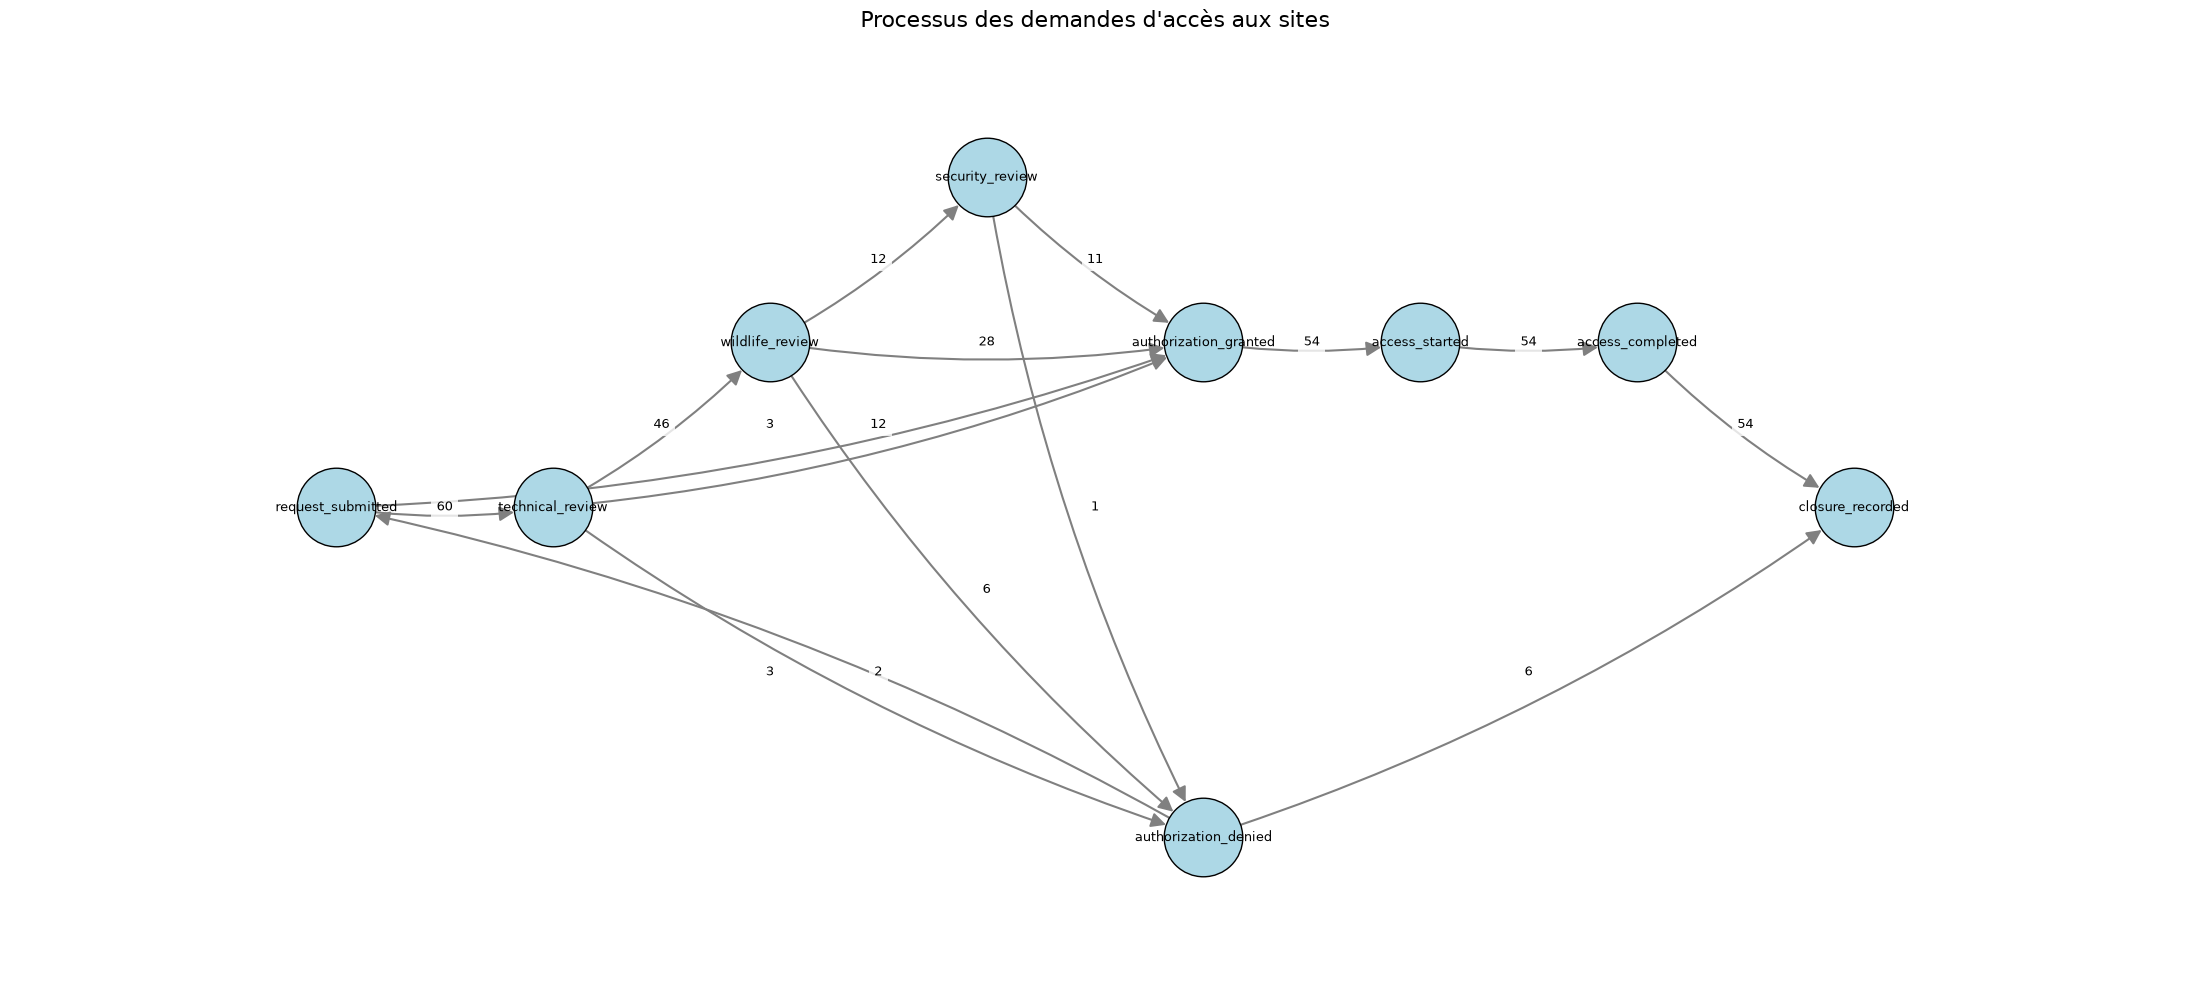

In [64]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for _, row in transitions.iterrows():
    G.add_edge(
        row["activity"],
        row["activite_suivante"],
        weight=row["nombre"]
    )

# Positionnement manuel des activités
pos = {
    "request_submitted": (0, 0),
    "technical_review": (2, 0),

    "wildlife_review": (4, 1),
    "security_review": (6, 2),

    "authorization_granted": (8, 1),
    "access_started": (10, 1),
    "access_completed": (12, 1),

    "authorization_denied": (8, -2),
    "closure_recorded": (14, 0)
}

plt.figure(figsize=(22, 10))

# Nœuds
nx.draw_networkx_nodes(
    G, pos,
    node_size=3200,
    node_color="lightblue",
    edgecolors="black"
)

# Étiquettes des nœuds
nx.draw_networkx_labels(
    G, pos,
    font_size=9
)

# Flèches
nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=22,
    node_size=3200,
    connectionstyle="arc3,rad=0.08",
    edge_color="gray",
    width=1.5
)

# Poids des transitions
poids = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=poids,
    font_size=9,
    rotate=False,
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8}
)

plt.title("Processus des demandes d'accès aux sites", fontsize=16)
plt.margins(0.15)
plt.axis("off")
plt.tight_layout()
plt.show()

Le graphe permet de visualiser les différentes étapes des demandes d'accès aux sites.

Nous observons un parcours principal allant de la soumission de la demande jusqu'à la clôture du dossier, avec différentes étapes de vérification et d'autorisation.

Certains dossiers suivent des parcours différents, notamment avec des examens de sécurité supplémentaires ou des refus suivis d'une nouvelle soumission.

Ces variations montrent que les demandes d'accès ne suivent pas toutes le même processus. Elles pourront être étudiées plus précisément afin de déterminer si certains parcours présentent des particularités.

### 7.4. Analyse des dépendances entre les activités — Heuristic Miner

Après avoir représenté les transitions entre les activités, nous allons utiliser le principe du Heuristic Miner présenté dans le CM5.

Cette méthode permet de mesurer la dépendance entre deux activités en comparant le nombre de transitions observées dans chaque sens.

L'objectif est d'identifier les enchaînements les plus caractéristiques des demandes d'accès et de distinguer les transitions fortes des transitions moins fréquentes.

In [65]:
# Calcul des scores de dépendance du Heuristic Miner

dependances = []

for a, b, data in G.edges(data=True):

    freq_ab = data["weight"]

    # Fréquence de la transition inverse
    freq_ba = G[b][a]["weight"] if G.has_edge(b, a) else 0

    score = (freq_ab - freq_ba) / (freq_ab + freq_ba + 1)

    dependances.append({
        "activite_depart": a,
        "activite_arrivee": b,
        "frequence": freq_ab,
        "dependance": round(score, 3)
    })

df_dependances = pd.DataFrame(dependances)

df_dependances = df_dependances.sort_values(
    "dependance",
    ascending=False
)

display(df_dependances)

,activite_depart,activite_arrivee,frequence,dependance
0,request_submitted,technical_review,60,0.984
5,access_started,access_completed,54,0.982
6,access_completed,closure_recorded,54,0.982
7,authorization_granted,access_started,54,0.982
2,technical_review,wildlife_review,46,0.979
8,wildlife_review,authorization_granted,28,0.966
3,technical_review,authorization_granted,12,0.923
9,wildlife_review,security_review,12,0.923
11,security_review,authorization_granted,11,0.917
10,wildlife_review,authorization_denied,6,0.857


Les résultats du Heuristic Miner montrent que les transitions les plus fréquentes présentent également des scores de dépendance élevés.

La transition `request_submitted → technical_review` possède le score le plus élevé (0,984), avec 60 occurrences. Les transitions liées à l'autorisation et à la réalisation de l'accès présentent également des scores proches de 1.

Nous observons aussi des transitions moins fréquentes, notamment `authorization_denied → request_submitted`, qui apparaît 3 fois avec un score de 0,750. Cela peut correspondre à une nouvelle soumission après un refus.

Ces résultats permettent d'identifier les principales étapes du processus ainsi que certains parcours moins fréquents, qui pourront être examinés plus précisément.

In [66]:
# Sélection des transitions les plus fortes

transitions_fortes = df_dependances[
    (df_dependances["dependance"] >= 0.90) &
    (df_dependances["frequence"] >= 5)
]

print("Nombre de transitions conservées :", len(transitions_fortes))

display(transitions_fortes)

Nombre de transitions conservées : 9


,activite_depart,activite_arrivee,frequence,dependance
0,request_submitted,technical_review,60,0.984
5,access_started,access_completed,54,0.982
6,access_completed,closure_recorded,54,0.982
7,authorization_granted,access_started,54,0.982
2,technical_review,wildlife_review,46,0.979
8,wildlife_review,authorization_granted,28,0.966
3,technical_review,authorization_granted,12,0.923
9,wildlife_review,security_review,12,0.923
11,security_review,authorization_granted,11,0.917


### 7.5. Visualisation du processus simplifié

Après avoir calculé les scores de dépendance, nous avons conservé les transitions présentant un score supérieur ou égal à 0,90 et une fréquence d'au moins 5 occurrences.

Ce filtrage a permis de passer de 15 à 9 transitions.

Nous allons représenter ces transitions sous forme d'un graphe orienté et pondéré afin de visualiser les principaux parcours des demandes d'accès.

Les transitions exclues sont conservées dans les données initiales pour l'analyse des parcours moins fréquents.

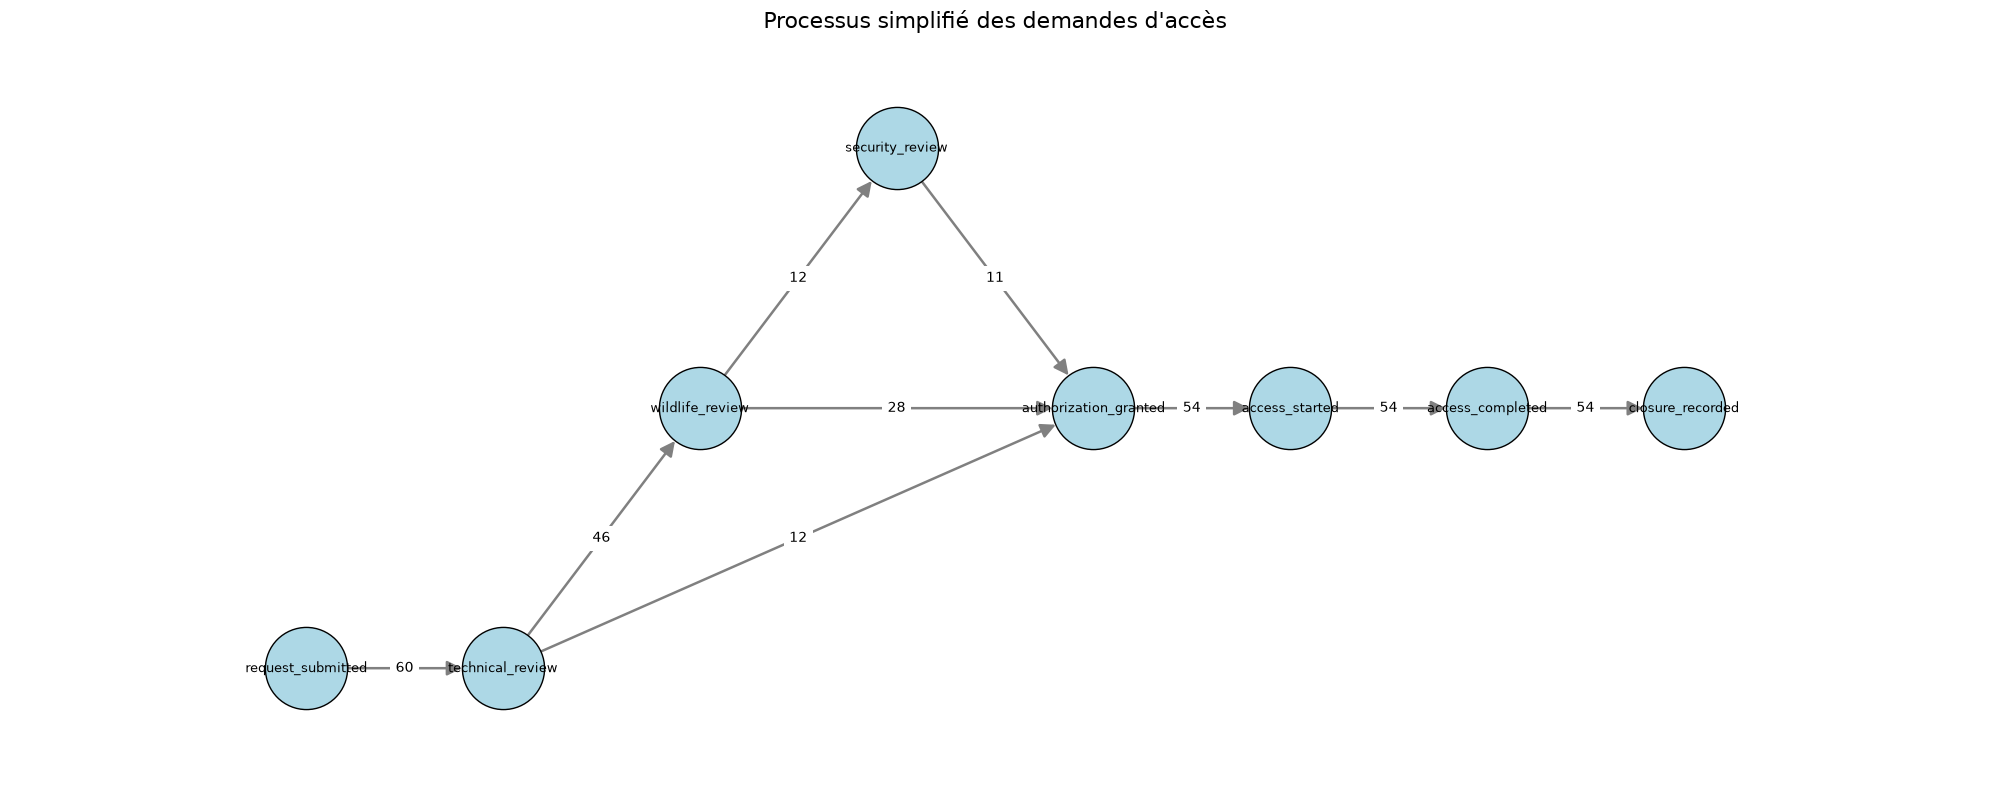

In [67]:
# Construction du graphe simplifié
G_filtre = nx.DiGraph()

for _, row in transitions_fortes.iterrows():
    G_filtre.add_edge(
        row["activite_depart"],
        row["activite_arrivee"],
        weight=row["frequence"]
    )

# Positions des activités
pos = {
    "request_submitted": (0, 0),
    "technical_review": (2, 0),
    "wildlife_review": (4, 1),
    "security_review": (6, 2),
    "authorization_granted": (8, 1),
    "access_started": (10, 1),
    "access_completed": (12, 1),
    "closure_recorded": (14, 1)
}

plt.figure(figsize=(20, 8))

nx.draw_networkx_nodes(
    G_filtre, pos,
    node_size=3500,
    node_color="lightblue",
    edgecolors="black"
)

nx.draw_networkx_labels(
    G_filtre, pos,
    font_size=9
)

nx.draw_networkx_edges(
    G_filtre, pos,
    arrows=True,
    arrowsize=22,
    node_size=3500,
    edge_color="gray",
    width=1.8
)

poids = nx.get_edge_attributes(G_filtre, "weight")

nx.draw_networkx_edge_labels(
    G_filtre, pos,
    edge_labels=poids,
    font_size=10,
    rotate=False,
    bbox={"facecolor": "white", "edgecolor": "none"}
)

plt.title("Processus simplifié des demandes d'accès", fontsize=16)
plt.margins(0.15)
plt.axis("off")
plt.tight_layout()
plt.show()

Le graphe simplifié met en évidence les principaux parcours des demandes d'accès aux sites.

Après la soumission et l'examen technique, certaines demandes passent par un examen de la faune, parfois complété par un examen de sécurité, avant d'obtenir une autorisation.

Les 54 demandes autorisées poursuivent ensuite le processus jusqu'à la clôture du dossier.

Le filtrage permet de mieux visualiser les étapes principales, mais il exclut certaines transitions moins fréquentes, notamment celles concernant les refus et les nouvelles soumissions.

Ces transitions restent présentes dans le graphe initial et pourront être étudiées séparément afin d'identifier d'éventuels parcours particuliers.

### 7.6. Analyse des transitions moins fréquentes

Le filtrage réalisé avec le Heuristic Miner a permis d'identifier les principales transitions du processus.

Cependant, certaines transitions moins fréquentes ont été exclues, notamment celles correspondant aux refus et aux nouvelles soumissions.

Nous allons examiner ces transitions afin de comprendre les parcours particuliers qui ne figurent pas dans le graphe simplifié.

In [68]:
# Identifier les transitions exclues du graphe simplifié

transitions_exclues = df_dependances[
    (df_dependances["dependance"] < 0.90) |
    (df_dependances["frequence"] < 5)
]

print("Nombre de transitions exclues :", len(transitions_exclues))

display(
    transitions_exclues[
        ["activite_depart", "activite_arrivee",
         "frequence", "dependance"]
    ]
)

Nombre de transitions exclues : 6


,activite_depart,activite_arrivee,frequence,dependance
10,wildlife_review,authorization_denied,6,0.857
13,authorization_denied,closure_recorded,6,0.857
14,authorization_denied,request_submitted,3,0.750
1,request_submitted,authorization_granted,3,0.750
4,technical_review,authorization_denied,2,0.667
12,security_review,authorization_denied,1,0.500


Nous avons identifié 6 transitions exclues lors du filtrage du Heuristic Miner.

La majorité de ces transitions concernent des refus d'autorisation. Nous observons notamment 6 transitions de `wildlife_review` vers `authorization_denied` et 3 transitions de `authorization_denied` vers `request_submitted`.

Ces dernières suggèrent que certaines demandes d'accès ont été soumises à nouveau après un refus.

Nous allons donc identifier les dossiers concernés afin d'étudier leurs parcours et de déterminer s'ils présentent des caractéristiques communes.

In [69]:
# Identifier les dossiers contenant un refus suivi d'une nouvelle soumission

df_access = donnees_clean["site_access_case_events"].copy()

df_access = df_access.sort_values(
    ["access_case_number", "event_time", "access_event_id"]
)

df_access["activite_suivante"] = (
    df_access.groupby("access_case_number")["activity"].shift(-1)
)

dossiers_resoumis = df_access[
    (df_access["activity"] == "authorization_denied") &
    (df_access["activite_suivante"] == "request_submitted")
]

display(
    dossiers_resoumis[
        [
            "access_case_number",
            "requesting_organization_name",
            "site_code",
            "access_purpose",
            "confidentiality_class"
        ]
    ]
)

,access_case_number,requesting_organization_name,site_code,access_purpose,confidentiality_class
73,ACC-2021-0010,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,restricted
98,ACC-2023-0013,Horizon Field Research Cooperative,AVL-VEL,habitat survey and sample documentation,confidential
114,ACC-2024-0015,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,standard


Les trois transitions correspondant à un refus suivi d'une nouvelle soumission concernent les dossiers `ACC-2021-0010`, `ACC-2023-0013` et `ACC-2024-0015`.

Ces trois dossiers appartiennent à la même organisation : Horizon Field Research Cooperative.

Deux d'entre eux concernent le site `AVL-MAR` et ont pour motif la surveillance acoustique et la maintenance d'équipements. Le troisième concerne le site `AVL-VEL` et porte sur l'étude de l'habitat et la documentation d'échantillons.

Ces dossiers avaient également été identifiés comme atypiques lors de l'analyse du nombre d'événements avec la méthode IQR.

Cette convergence entre la détection d'anomalies et le Process Mining nous incite à examiner plus précisément leurs parcours. Toutefois, ces résultats ne suffisent pas à conclure à une irrégularité.

In [70]:
# Vérifier les parcours complets des trois dossiers

dossiers = [
    "ACC-2021-0010",
    "ACC-2023-0013",
    "ACC-2024-0015"
]

parcours = df_access[
    df_access["access_case_number"].isin(dossiers)
].sort_values(["access_case_number", "event_time", "access_event_id"])

display(
    parcours[
        [
            "access_case_number",
            "event_time",
            "activity",
            "new_status"
        ]
    ]
)

,access_case_number,event_time,activity,new_status
70,ACC-2021-0010,2021-04-19 09:00:00,request_submitted,submitted
71,ACC-2021-0010,2021-04-25 09:00:00,technical_review,technical_review
72,ACC-2021-0010,2021-04-30 09:00:00,wildlife_review,wildlife_review
73,ACC-2021-0010,2021-05-06 09:00:00,authorization_denied,returned
74,ACC-2021-0010,2021-05-08 09:00:00,request_submitted,resubmitted
75,ACC-2021-0010,2021-05-10 09:00:00,authorization_granted,authorized
76,ACC-2021-0010,2021-05-20 18:00:00,access_started,active
77,ACC-2021-0010,2021-05-21 03:00:00,access_completed,completed
78,ACC-2021-0010,2021-05-23 11:00:00,closure_recorded,closed
94,ACC-2023-0013,2023-10-09 09:00:00,request_submitted,submitted


#### Analyse des parcours après refus

Nous avons étudié les parcours complets des trois dossiers présentant un refus suivi d'une nouvelle soumission.

Les dossiers `ACC-2021-0010`, `ACC-2023-0013` et `ACC-2024-0015` concernent tous Horizon Field Research Cooperative.

Nous observons une séquence similaire dans les trois cas : un refus d'autorisation, une nouvelle soumission deux jours après, puis une autorisation accordée deux jours plus tard.

Les accès ont ensuite été réalisés dix jours après l'autorisation, entre 18 h et 3 h du matin, avant la clôture des dossiers.

Cette répétition des délais et des horaires constitue un résultat intéressant. Elle pourrait correspondre à une procédure standardisée ou à une organisation particulière des interventions.

Ces observations ne permettent toutefois pas de conclure à une irrégularité. Il serait nécessaire de comparer ces horaires et délais avec ceux des autres demandes d'accès.

In [71]:
# Horaires de début des accès pour tous les dossiers

debut_acces = df_access[
    df_access["activity"] == "access_started"
].copy()

debut_acces["heure_debut"] = debut_acces["event_time"].dt.hour

print("Répartition des heures de début d'accès :")
display(debut_acces["heure_debut"].value_counts().sort_index())

Répartition des heures de début d'accès :


heure_debut
17    36
18    18
Name: count, dtype: int64

Nous avons comparé les horaires de début des trois dossiers étudiés avec ceux de l'ensemble des accès réalisés.

Sur les 54 accès, 36 commencent à 17 h (66,7 %) et 18 commencent à 18 h (33,3 %).

Les trois dossiers présentant un refus suivi d'une nouvelle soumission commencent tous à 18 h. Cependant, cet horaire concerne également d'autres dossiers et ne constitue donc pas, à lui seul, une anomalie.

Les particularités les plus intéressantes restent la répétition des refus, des nouvelles soumissions et des délais observés pour une même organisation.

## 8. Analyse des données spatiales et temporelles

Nous allons étudier l'évolution temporelle des demandes d'accès aux sites afin d'identifier d'éventuelles périodes d'activité particulière.

Pour cette analyse, nous utilisons les 60 dossiers regroupés précédemment, afin de ne pas compter plusieurs fois les événements appartenant à une même demande d'accès.

Nous commençons par observer la répartition des demandes selon leur année de création.

,annee,nombre_demandes
0,2015,2
1,2016,1
2,2017,4
3,2018,8
4,2019,8
5,2020,3
6,2021,6
7,2022,10
8,2023,8
9,2024,8


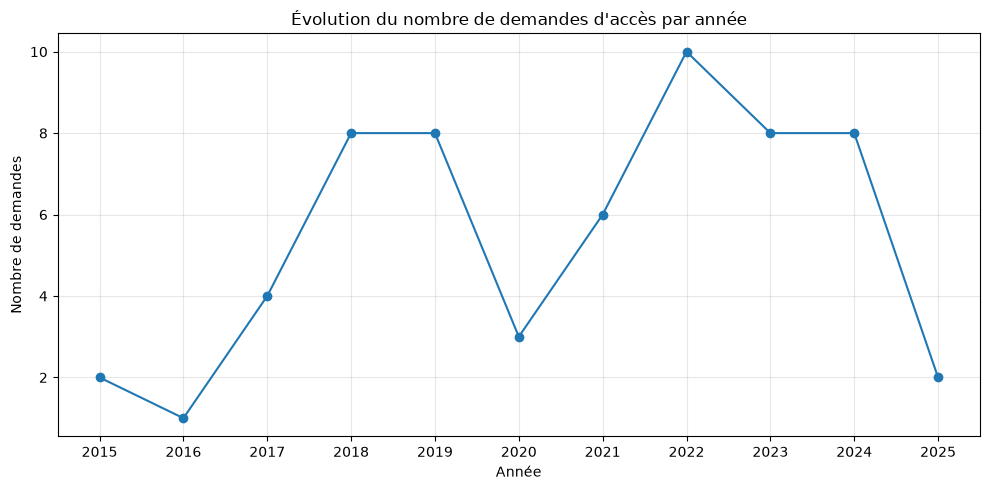

In [72]:
# Nombre de demandes d'accès par année

df_temporel = df_dossiers.copy()

df_temporel["annee"] = df_temporel["date_debut"].dt.year

demandes_par_annee = (
    df_temporel.groupby("annee")
    .size()
    .reset_index(name="nombre_demandes")
)

display(demandes_par_annee)

# Visualisation
plt.figure(figsize=(10, 5))

plt.plot(
    demandes_par_annee["annee"],
    demandes_par_annee["nombre_demandes"],
    marker="o"
)

plt.title("Évolution du nombre de demandes d'accès par année")
plt.xlabel("Année")
plt.ylabel("Nombre de demandes")
plt.xticks(demandes_par_annee["annee"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Interprétation de l'évolution temporelle

Nous avons étudié l'évolution annuelle des demandes d'accès aux sites entre 2015 et 2025.

Nous observons une augmentation globale du nombre de demandes entre 2015 et 2019, suivie d'une diminution en 2020 avec seulement 3 demandes.

L'année 2022 présente le nombre le plus élevé avec 10 demandes. En 2023 et 2024, nous observons 8 demandes par année, avant une diminution en 2025.

Ces résultats montrent que l'activité varie selon les années. Cependant, ces variations ne suffisent pas à identifier une anomalie ou à expliquer le narratif caché.

Nous allons donc examiner les organisations à l'origine de ces demandes afin de déterminer si certaines contribuent davantage aux variations observées.

In [73]:
# Nombre de demandes par année et par organisation

demandes_organisations = (
    df_temporel.groupby(
        ["annee", "requesting_organization_name"]
    )
    .size()
    .reset_index(name="nombre_demandes")
)

# Organisations ayant déposé le plus de demandes
top_organisations = (
    df_temporel["requesting_organization_name"]
    .value_counts()
    .head(5)
    .index
)

# Conserver uniquement ces organisations
evolution_organisations = demandes_organisations[
    demandes_organisations["requesting_organization_name"].isin(top_organisations)
]

display(
    evolution_organisations.sort_values(
        ["annee", "nombre_demandes"],
        ascending=[True, False]
    )
)

,annee,requesting_organization_name,nombre_demandes
0,2015,Nordhaven Maritime Safety Agency,1
6,2017,Valenne Laboratory Materials,1
9,2018,Horizon Field Research Cooperative,3
10,2018,Interregional Procurement Cooperative,1
11,2018,Nordhaven Refrigeration Works,1
15,2019,Horizon Field Research Cooperative,3
19,2020,Horizon Field Research Cooperative,2
21,2021,Horizon Field Research Cooperative,2
24,2021,Nordhaven Maritime Safety Agency,1
29,2022,Horizon Field Research Cooperative,1


#### Évolution temporelle des principales organisations

Nous avons étudié l'évolution annuelle des demandes d'accès pour les cinq organisations les plus représentées.

Nous observons que Horizon Field Research Cooperative apparaît régulièrement entre 2018 et 2025, avec une activité particulièrement importante en 2018, 2019 et 2024 (3 demandes par année).

Cependant, l'année 2022, qui présente le nombre total de demandes le plus élevé, ne correspond pas à une augmentation particulière de l'activité de cette organisation.

Ces résultats montrent que Horizon Field Research Cooperative est régulièrement présente dans les demandes d'accès, mais qu'elle n'explique pas à elle seule les variations observées.

Cette organisation avait également été identifiée lors de l'analyse des parcours comprenant des refus suivis de nouvelles soumissions.

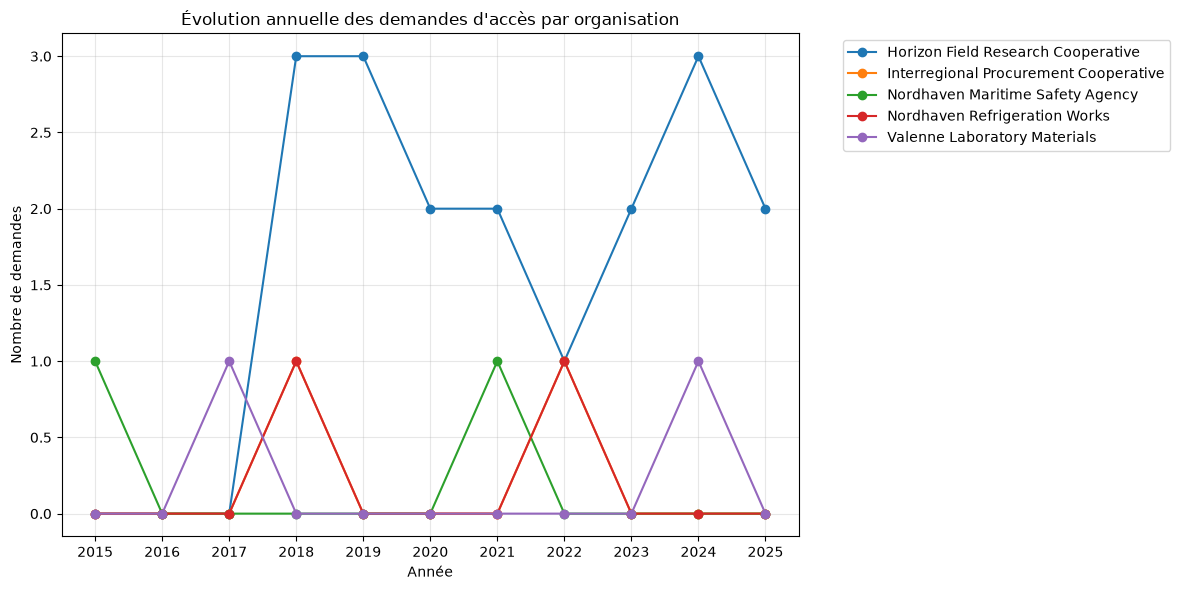

In [74]:
# Tableau des demandes par année et par organisation
tableau_evolution = (
    evolution_organisations.pivot(
        index="annee",
        columns="requesting_organization_name",
        values="nombre_demandes"
    )
    .reindex(demandes_par_annee["annee"])
    .fillna(0)
)

# Graphique
plt.figure(figsize=(12, 6))

for organisation in tableau_evolution.columns:
    plt.plot(
        tableau_evolution.index,
        tableau_evolution[organisation],
        marker="o",
        label=organisation
    )

plt.title("Évolution annuelle des demandes d'accès par organisation")
plt.xlabel("Année")
plt.ylabel("Nombre de demandes")
plt.xticks(tableau_evolution.index)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Le graphique montre que Horizon Field Research Cooperative est l'organisation la plus régulièrement présente parmi les cinq organisations étudiées, avec des demandes d'accès chaque année entre 2018 et 2025.

Les autres organisations présentent des activités plus ponctuelles, avec généralement une seule demande durant les années où elles apparaissent.

Nous observons également que les années de forte activité globale ne correspondent pas systématiquement aux années où Horizon Field Research Cooperative dépose le plus de demandes.

Cette régularité est intéressante puisque cette organisation avait déjà été identifiée dans plusieurs dossiers présentant un refus suivi d'une nouvelle soumission. Cependant, sa fréquence d'apparition ne permet pas à elle seule de conclure à une activité anormale.

In [75]:
# Nombre de demandes d'accès par site

demandes_par_site = (
    df_dossiers["site_code"]
    .value_counts()
    .reset_index()
)

demandes_par_site.columns = ["site_code", "nombre_demandes"]

print("Nombre de sites différents :", df_dossiers["site_code"].nunique())

display(demandes_par_site.head(20))

Nombre de sites différents : 50


,site_code,nombre_demandes
0,KNT-KES,3
1,AVL-MAR,3
2,TMB-NAC,2
3,TMB-PEL,2
4,KNT-LUM,2
5,AVL-VEL,2
6,KNT-SEN,2
7,AVL-ORR,2
8,KNT-DMJ,1
9,KNT-VXR,1


### Répartition des demandes d'accès par site

Nous avons étudié la répartition des 60 demandes d'accès entre les différents sites.

Les sites `KNT-KES` et `AVL-MAR` sont les plus représentés, avec 3 demandes chacun. Plusieurs autres sites, notamment `AVL-VEL`, apparaissent deux fois.

Nous remarquons que les sites `AVL-MAR` et `AVL-VEL` sont également concernés par les trois dossiers de Horizon Field Research Cooperative présentant un refus suivi d'une nouvelle soumission.

Toutefois, les demandes restent globalement dispersées entre de nombreux sites. Aucun site ne concentre une part importante de l'ensemble des demandes.

Nous allons donc examiner les organisations et les motifs d'accès associés aux sites les plus représentés afin de rechercher d'éventuelles caractéristiques communes.

In [76]:
# Examiner les dossiers associés aux sites les plus fréquents

sites_interessants = [
    "KNT-KES",
    "AVL-MAR",
    "AVL-VEL"
]

dossiers_sites = df_dossiers[
    df_dossiers["site_code"].isin(sites_interessants)
]

display(
    dossiers_sites[
        [
            "access_case_number",
            "site_code",
            "requesting_organization_name",
            "access_purpose",
            "equipment_category",
            "confidentiality_class"
        ]
    ].sort_values("site_code")
)

,access_case_number,site_code,requesting_organization_name,access_purpose,equipment_category,confidentiality_class
9,ACC-2018-0003,AVL-MAR,Horizon Field Research Cooperative,habitat survey and sample documentation,protective field equipment,restricted
27,ACC-2021-0010,AVL-MAR,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted
51,ACC-2024-0015,AVL-MAR,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,acoustic and camera equipment,standard
17,ACC-2019-0006,AVL-VEL,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted
43,ACC-2023-0013,AVL-VEL,Horizon Field Research Cooperative,habitat survey and sample documentation,protective field equipment,confidential
8,ACC-2018-0002,KNT-KES,Horizon Field Research Cooperative,night wildlife monitoring programme,portable monitoring and cold-storage equipment,confidential
26,ACC-2021-0009,KNT-KES,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,protective field equipment,standard
50,ACC-2024-0014,KNT-KES,Horizon Field Research Cooperative,night wildlife monitoring programme,acoustic and camera equipment,restricted


### Analyse des sites les plus représentés

Nous avons examiné les dossiers associés aux trois sites les plus fréquents : `AVL-MAR`, `AVL-VEL` et `KNT-KES`.

Nous constatons que les 8 demandes concernant ces sites proviennent de la même organisation : Horizon Field Research Cooperative.

Les activités déclarées concernent principalement la surveillance acoustique, la maintenance d'équipements, la documentation d'échantillons et la surveillance nocturne de la faune.

Certains dossiers mentionnent également des équipements portables de surveillance et de stockage frigorifique.

Nous remarquons que les trois dossiers présentant un refus suivi d'une nouvelle soumission concernent les sites `AVL-MAR` et `AVL-VEL`.

Ces résultats mettent en évidence une présence répétée de Horizon Field Research Cooperative sur plusieurs sites, avec des activités et des équipements variés.

Ces observations pourront être croisées avec les documents institutionnels et les autres données afin de rechercher d'éventuels liens avec le narratif caché.

In [77]:
# Comparaison des motifs d'accès selon les sites

tableau_sites_motifs = pd.crosstab(
    dossiers_sites["site_code"],
    dossiers_sites["access_purpose"]
)

display(tableau_sites_motifs)

access_purpose,acoustic monitoring and equipment maintenance,habitat survey and sample documentation,night wildlife monitoring programme
site_code,,,
AVL-MAR,2,1,0
AVL-VEL,1,1,0
KNT-KES,1,0,2


La comparaison des motifs d'accès montre que la surveillance acoustique et la maintenance d'équipements sont présentes sur les trois sites étudiés.

Les activités de documentation d'échantillons apparaissent sur `AVL-MAR` et `AVL-VEL`, tandis que les activités de surveillance nocturne de la faune sont concentrées sur `KNT-KES`.

Ces huit demandes concernent Horizon Field Research Cooperative. Nous observons donc des activités récurrentes sur plusieurs sites, avec certaines particularités selon leur localisation.

Ces résultats constituent des pistes à rapprocher des documents institutionnels, notamment ceux évoquant la collecte d'échantillons et leur stockage. Cependant, aucun lien direct n'est encore établi.

In [78]:
# Vérifier les informations géographiques disponibles
df_sites = donnees_clean["licensed_facilities"]

display(
    df_sites[
        ["facility_name", "latitude", "longitude"]
    ]
)

,facility_name,latitude,longitude
0,Asterion Central Clinical Campus,47.20,7.51
1,Asterion Avelora Executive Clinic,7.35,101.62
2,Threshold Earth Avelora Laboratory,7.50,101.75


### Limites de l'analyse spatiale

Nous avons examiné les coordonnées géographiques disponibles dans le fichier `licensed_facilities`.

Ce fichier contient les coordonnées de trois établissements, mais celles-ci ne correspondent pas directement aux codes des sites présents dans les demandes d'accès.

Nous ne pouvons donc pas calculer de distances géographiques fiables entre les sites étudiés ni appliquer les méthodes de regroupement spatial du CM6 à ces demandes.

Nous avons ainsi limité notre analyse à la répartition des demandes par site et à leur évolution temporelle, sans inventer de coordonnées géographiques.

## 9. Analyse des données textuelles

Nous allons appliquer des techniques de Text Mining aux documents institutionnels et aux documents publics ou d'investigation.

L'objectif est d'identifier les mots et expressions récurrents, de rechercher des relations entre les documents et de repérer des informations susceptibles de contribuer à la compréhension du narratif caché.

Nous commençons par explorer la structure des deux tables afin d'identifier les colonnes textuelles exploitables.

In [79]:
# Exploration des tables contenant des documents textuels

for nom_table in [
    "institutional_memos",
    "public_and_investigative_documents"
]:
    df = donnees_clean[nom_table]

    print(f"\nTable : {nom_table}")
    print("Nombre de documents :", len(df))
    print("\nColonnes disponibles :")
    print(df.columns.tolist())


Table : institutional_memos
Nombre de documents : 30

Colonnes disponibles :
['document_id', 'document_date', 'document_type', 'author_name', 'author_organization', 'recipient_text', 'subject_line', 'text', 'related_purchase_order', 'related_shipment_number', 'related_case_number', 'visibility_level']

Table : public_and_investigative_documents
Nombre de documents : 40

Colonnes disponibles :
['document_id', 'document_date', 'collection', 'document_type', 'author_name', 'author_organization', 'named_location', 'title', 'text', 'public_or_restricted', 'source_reference']
